In [19]:
# 1. Убедимся, что GPU на месте (после смены Runtime Type)
!nvidia-smi

# 2. Установим системные зависимости и Ollama
!sudo apt-get update -qq
!sudo apt-get install -y -qq zstd
!curl -fsSL https://ollama.com/install.sh | sh

# 3. Запустим сервер Ollama в фоне
!nohup ollama serve > ollama.log 2>&1 &

# 4. Дадим серверу пару секунд запуститься и проверим, что он жив
import time
time.sleep(5)
!ollama list

Wed Oct 28 07:19:38 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   73C    P0             33W /   70W |    6419MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [20]:
# Скачиваем модель. Для T4 16GB VRAM этого более чем достаточно.
!ollama pull qwen2.5:7b

# Проверяем, что модель загрузилась
!ollama list


NAME          ID              SIZE      MODIFIED               
qwen2.5:7b    845dbda0ea48    4.7 GB    Less than a second ago    


In [46]:
import os, re, json, zipfile, requests, time, pickle
from pathlib import Path
from typing import List, Optional, Tuple
import numpy as np
import faiss
from sentence_transformers import SentenceTransformer, CrossEncoder
from huggingface_hub import list_repo_files
from tqdm.auto import tqdm
from langchain_ollama import ChatOllama

# ---------- КОНФИГ ----------
# Для TechQA используем сильную мультиязычную модель, которая отлично работает на GPU
EMBEDDER_NAME = "BAAI/bge-base-en-v1.5"

CHUNK_SIZE    = 1000          # Можно увеличить, т.к. T4 быстрый
CHUNK_OVERLAP = 150

TOP_K         = 10
SIM_THRESHOLD = 0.75          # Для TechQA (is_impossible) порог почти не работает, но пусть будет
KEEP_RATIO    = 0.85
MAX_CONTEXT_CHARS = 6000      # Увеличиваем, т.к. контекстное окно LLM больше

# ---------- OLLAMA / LLM ----------
OLLAMA_MODEL          = "qwen2.5:7b"
OLLAMA_NUM_CTX        = 8192   # Увеличиваем контекст, памяти хватает
OLLAMA_NUM_GPU        = -1     # -1 = использовать все слои на GPU
OLLAMA_REPEAT_PENALTY = 1.1
OLLAMA_NUM_PREDICT    = 800

# ---------- NLI ----------
NLI_MODEL_NAME = "cross-encoder/nli-deberta-v3-large"

REFUSAL_PHRASE_EN = ("I cannot answer this question because the provided documents "
                     "do not contain the necessary information.")
REFUSAL_PHRASE = REFUSAL_PHRASE_EN

In [22]:
DATA_DIR = Path("techqa_data")
DATA_DIR.mkdir(exist_ok=True)
CORPUS_DIR = DATA_DIR / "corpus"
CORPUS_DIR.mkdir(exist_ok=True)

BASE_URL = "https://huggingface.co/datasets/nvidia/TechQA-RAG-Eval/resolve/main/"

# Скачиваем train.json
train_path = DATA_DIR / "train.json"
if not train_path.exists():
    print("Скачиваем train.json...")
    r = requests.get(BASE_URL + "train.json", timeout=60)
    r.raise_for_status()
    train_path.write_bytes(r.content)
    print(f"✅ train.json: {train_path.stat().st_size / 1024:.1f} KB")

# Скачиваем corpus.zip
zip_path = DATA_DIR / "corpus.zip"
if not zip_path.exists():
    print("Скачиваем corpus.zip (~46 MB)...")
    r = requests.get(BASE_URL + "corpus.zip", timeout=300, stream=True)
    r.raise_for_status()
    total = int(r.headers.get("content-length", 0))
    with open(zip_path, "wb") as f, tqdm(total=total, unit="B", unit_scale=True, desc="corpus.zip") as pbar:
        for chunk in r.iter_content(chunk_size=8192):
            f.write(chunk)
            pbar.update(len(chunk))

# Распаковываем
if not any(CORPUS_DIR.iterdir()):
    print("Распаковываем корпус...")
    with zipfile.ZipFile(zip_path, "r") as z:
        z.extractall(CORPUS_DIR)

# Загружаем train.json
with open(train_path, "r", encoding="utf-8") as f:
    train_data = json.load(f)
print(f"Загружено вопросов: {len(train_data)}")

Загружено вопросов: 910


In [14]:
documents, doc_names = [], []
for txt_file in sorted(CORPUS_DIR.rglob("*.txt")):
    try:
        text = txt_file.read_text(encoding="utf-8", errors="ignore")
        text = re.sub(r'\s+', ' ', text).strip()
        if len(text) > 100:
            documents.append(text)
            doc_names.append(str(txt_file.relative_to(CORPUS_DIR)))
    except Exception as e:
        print(f"⚠️ Пропущен {txt_file.name}: {e}")

print(f"Загружено документов: {len(documents)}")

def chunk_text(text: str, chunk_size: int = CHUNK_SIZE, overlap: int = CHUNK_OVERLAP) -> List[str]:
    chunks, start = [], 0
    while start < len(text):
        end = min(start + chunk_size, len(text))
        chunk = text[start:end].strip()
        if len(chunk) > 50:
            chunks.append(chunk)
        start += chunk_size - overlap
    return chunks

def clean_text(text: str) -> str:
    """Убирает markdown-артефакты парсинга (* * , **, одиночные *)."""
    text = re.sub(r'\*\s*\*', ' ', text)
    text = re.sub(r'\*+', '', text)
    text = re.sub(r'\s+', ' ', text)
    return text.strip()

all_chunks, chunk_metadata = [], []
for doc_name, doc_text in zip(doc_names, documents):
    for i, chunk in enumerate(chunk_text(doc_text)):
        cleaned = clean_text(chunk)
        if len(cleaned) > 50:
            all_chunks.append(cleaned)
            chunk_metadata.append({"doc_name": doc_name, "chunk_index": i})

print(f"Всего чанков после очистки: {len(all_chunks)}")

Загружено документов: 28481
Всего чанков после очистки: 127040


In [15]:
EMB_CACHE_PATH = Path("techqa_chunk_embeddings_bge_base.pkl")

# T4 GPU доступен, поэтому устройство будет "cuda"
# Было:
# embedder = SentenceTransformer(EMBEDDER_NAME, device="cuda" if os.environ.get("CUDA_VISIBLE_DEVICES") else "cpu")

# Стало:
import torch

device = "cuda" if torch.cuda.is_available() else "cpu"
embedder = SentenceTransformer(EMBEDDER_NAME, device=device)
print(f"Модель: {EMBEDDER_NAME} | устройство: {embedder.device}")
print(f"torch.cuda.is_available() = {torch.cuda.is_available()}")
print(f"GPU: {torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'нет'}")

assert embedder.device.type == "cuda", \
    "⚠️ Модель на CPU — проверьте, что Runtime → Change runtime type → T4 GPU"
print(f"Модель: {EMBEDDER_NAME} | устройство: {embedder.device}")

cached = None
if EMB_CACHE_PATH.exists():
    with open(EMB_CACHE_PATH, "rb") as f:
        cached = pickle.load(f)
    ok = (cached.get("num_chunks") == len(all_chunks)
          and cached.get("embedder_name") == EMBEDDER_NAME)
    if ok:
        print(f"✅ Кэш валиден: shape={cached['embeddings'].shape}")
    else:
        cached = None

if cached is None:
    # bge-m3 не требует префиксов, но для симметрии можно оставить
    texts = all_chunks

    # Замер на маленькой порции (быстро на GPU)
    probe = min(32, len(texts))
    _ = embedder.encode(texts[:probe], normalize_embeddings=True, batch_size=32)
    t0 = time.time()
    _ = embedder.encode(texts[:probe], normalize_embeddings=True, batch_size=32)
    per = (time.time() - t0) / probe
    print(f"⏱️ ~{per*1000:.1f} мс/чанк → оценка: ~{per * len(texts) / 60:.1f} мин")

    t0 = time.time()
    chunk_embeddings = embedder.encode(
        texts,
        normalize_embeddings=True,
        convert_to_numpy=True,
        batch_size=64,          # На GPU можно и больше
        show_progress_bar=True,
    )
    print(f"✅ Готово за {(time.time()-t0)/60:.1f} мин")

    with open(EMB_CACHE_PATH, "wb") as f:
        pickle.dump({
            "num_chunks": len(all_chunks),
            "embedder_name": EMBEDDER_NAME,
            "embeddings": chunk_embeddings,
        }, f)
    print(f"💾 Сохранено в {EMB_CACHE_PATH}")
else:
    chunk_embeddings = cached["embeddings"]

# FAISS
t0 = time.time()
index = faiss.IndexFlatIP(chunk_embeddings.shape[1])
index.add(chunk_embeddings.astype("float32"))
print(f"✅ FAISS за {time.time()-t0:.2f} с: {index.ntotal} векторов")

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/94.6k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/52.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/777 [00:00<?, ?B/s]

...

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Модель: BAAI/bge-base-en-v1.5 | устройство: cuda:0
torch.cuda.is_available() = True
GPU: Tesla T4
Модель: BAAI/bge-base-en-v1.5 | устройство: cuda:0
⏱️ ~21.2 мс/чанк → оценка: ~44.8 мин


Batches:   0%|          | 0/1985 [00:00<?, ?it/s]

✅ Готово за 57.2 мин
💾 Сохранено в techqa_chunk_embeddings_bge_base.pkl
✅ FAISS за 0.65 с: 127040 векторов


In [23]:
def retrieve(query: str, top_k: int = TOP_K,
             threshold: float = SIM_THRESHOLD,
             keep_ratio: float = KEEP_RATIO,
             max_chars: int = MAX_CONTEXT_CHARS
             ) -> Tuple[Optional[List[str]], Optional[List[dict]], float]:
    q_emb = embedder.encode(
        [query],
        normalize_embeddings=True, convert_to_numpy=True,
    ).astype("float32")

    scores, idxs = index.search(q_emb, top_k)
    scores, idxs = scores[0], idxs[0]
    best = float(scores[0])

    if best < threshold:
        return None, None, best

    kept_chunks, kept_meta, total = [], [], 0
    for score, idx in zip(scores, idxs):
        if score < best * keep_ratio:
            continue
        c = all_chunks[idx]
        if total + len(c) > max_chars and kept_chunks:
            break
        kept_chunks.append(c)
        kept_meta.append(chunk_metadata[idx])
        total += len(c)
    return kept_chunks, kept_meta, best

In [47]:
# =====================================================================
# 1. ИНИЦИАЛИЗАЦИЯ LLM (теперь на GPU!)
# =====================================================================
llm = ChatOllama(
    model=OLLAMA_MODEL,
    temperature=0.1,
    num_ctx=OLLAMA_NUM_CTX,
    num_gpu=OLLAMA_NUM_GPU,        # -1 = все слои на GPU
    repeat_penalty=OLLAMA_REPEAT_PENALTY,
    num_predict=OLLAMA_NUM_PREDICT,
    base_url="http://localhost:11434",
)

try:
    probe = llm.invoke("Reply with one word only: ready").content.strip()
    print(f"✅ LLM доступна. Тест: {probe!r}")
except Exception as e:
    print(f"❌ LLM недоступна: {e}")

# =====================================================================
# 2. ИНИЦИАЛИЗАЦИЯ NLI
# =====================================================================
NLI_AVAILABLE = False
_nli_entail_idx = 1
_nli_contradict_idx = 0

try:
    nli_model = CrossEncoder(NLI_MODEL_NAME, device=device)
    _labels = nli_model.model.config.id2label
    _nli_entail_idx = next((i for i, l in _labels.items() if 'entail' in l.lower()), 1)
    _nli_contradict_idx = next((i for i, l in _labels.items() if 'contradict' in l.lower()), 0)
    NLI_AVAILABLE = True
    print(f"✅ NLI загружена: entail_idx={_nli_entail_idx}, contradict_idx={_nli_contradict_idx}")
except Exception as e:
    print(f"⚠️ NLI недоступна: {e}")

# =====================================================================
# 3. ПРОМПТ С ОБЯЗАТЕЛЬНОЙ ЦИТАТОЙ
# =====================================================================
SYSTEM_PROMPT = """You are a strict technical support assistant.
Answer ONLY based on the provided CONTEXT. Answer in English.
Before answering, you MUST find a specific sentence in the context that directly supports your answer.
If no such sentence exists, you MUST refuse."""

def _build_prompt(query: str, context: str) -> str:
    return f"""{SYSTEM_PROMPT}

CONTEXT:
{context}

QUESTION: {query}

INSTRUCTIONS:
1. First, find and quote the EXACT sentence from the context that supports the answer.
2. If you cannot find such a sentence, respond EXACTLY:
   REFUSAL: {REFUSAL_PHRASE}
3. Otherwise, respond in this format:
   SUPPORT: "<exact sentence from context>"
   ANSWER: <your answer in 1-3 sentences>

Your response:"""

# =====================================================================
# 4. ХЕЛПЕРЫ
# =====================================================================
def _normalize(s: str) -> str:
    return re.sub(r'\s+', ' ', s.lower().strip())

def _looks_like_refusal(answer: str) -> bool:
    a = answer.strip().lower()
    if len(a) > 300:
        return False
    return (
        "cannot answer" in a
        or "do not contain" in a
        or "no necessary information" in a
        or "refusal:" in a[:20]
    ) and not any(w in a for w in ["however", "but ", "nevertheless", "according to"])

def strip_markdown(text: str) -> str:
    text = re.sub(r'\*\*(.+?)\*\*', r'\1', text)
    text = re.sub(r'(?<!\*)\*(?!\*)(.+?)(?<!\*)\*(?!\*)', r'\1', text)
    text = re.sub(r'`(.+?)`', r'\1', text)
    return text

def dedupe_repeated_lines(text: str, max_dupes: int = 1) -> str:
    seen, result = {}, []
    for line in text.split("\n"):
        key = line.strip().lower()
        if not key:
            result.append(line); continue
        seen[key] = seen.get(key, 0) + 1
        if seen[key] <= max_dupes:
            result.append(line)
    return "\n".join(result)

def answer_is_clean(answer: str) -> Tuple[bool, str]:
    if _looks_like_refusal(answer):
        return True, ""
    if re.search(r'[\u4e00-\u9fff\u3040-\u30ff\uac00-\ud7af]', answer):
        return False, "восточноазиатские символы"
    # Underscore ловим только при наличии кириллицы рядом
    if re.search(r'[А-Яа-яЁё]+_\w+|\w+_[А-Яа-яЁё]+', answer):
        return False, "underscore внутри слов с кириллицей"
    # Фейковые номера — только 5+ уровней
    if re.search(r'\b\d+(?:\.\d+){5,}\b', answer):
        return False, "фейковые многоуровневые номера"
    return True, ""

def _support_is_in_context(support: str, context: str, min_word_overlap: float = 0.70) -> bool:
    if len(support) < 20:
        return False
    s_norm = _normalize(support).strip('"\'').strip()
    c_norm = _normalize(context)
    if s_norm in c_norm:
        return True
    s_words = {w for w in re.findall(r'\w+', s_norm) if len(w) > 3}
    if not s_words:
        return False
    c_words = set(re.findall(r'\w+', c_norm))
    overlap = len(s_words & c_words) / len(s_words)
    return overlap >= min_word_overlap

from scipy.special import softmax

def answer_is_grounded_nli(answer: str, support: str,
                           context: str = "",
                           debug: bool = False) -> Tuple[bool, str]:
    """
    Проверяет, не противоречит ли ответ контексту.

    Логика:
    - SUPPORT от LLM — это узкая цитата, ответ часто шире неё.
    - Сравниваем ответ с ПОЛНЫМ контекстом (там все детали).
    - Отклоняем ТОЛЬКО при явном противоречии (contradict > 0.5).
    - Нейтральность (entail низкий, contradict низкий) НЕ наказуема.
    """
    if not NLI_AVAILABLE or _looks_like_refusal(answer):
        return True, ""

    # ⚠️ Полный контекст, а не узкий SUPPORT
    premise = context if context and len(context) > 100 else support
    if not premise or len(premise) < 50:
        return False, "empty_premise"

    sents = [s.strip() for s in re.split(r'(?<=[.!?])\s+', answer)
             if len(s.strip()) > 15]
    if not sents:
        return True, ""

    pairs = [(premise, s) for s in sents]
    logits = nli_model.predict(pairs)
    probs = softmax(logits, axis=1)

    contradictions = []
    for s, pr in zip(sents, probs):
        e = float(pr[_nli_entail_idx])
        c = float(pr[_nli_contradict_idx])
        if debug:
            print(f"  NLI(ctx): entail={e:.3f}, contradict={c:.3f} | {s[:80]}...")
        # ⚠️ только явное противоречие
        if c > 0.5:
            contradictions.append(s)

    if contradictions:
        return False, f"{len(contradictions)}/{len(sents)} предложений противоречат контексту"
    return True, ""

def llm_self_verify(query: str, context: str, answer: str) -> Tuple[bool, str]:
    """
    Мягкая версия: спрашиваем, ПРОТИВОРЕЧИТ ли ответ контексту,
    а не «содержится ли он явно». Противоречие — единственный
    надёжный сигнал для 7B-модели.
    """
    verify_prompt = f"""Does the proposed answer CONTRADICT the context, or does it merely go beyond it?

CONTEXT:
{context[:3000]}

QUESTION: {query}

PROPOSED ANSWER: {answer}

Rules:
- If the answer says something the context says is FALSE → reply CONTRADICTS
- If the answer is reasonable but not explicitly stated → reply EXTENDS
- If the answer is directly supported → reply SUPPORTS

Reply with exactly one word: CONTRADICTS, EXTENDS, or SUPPORTS."""

    try:
        verdict = llm.invoke(verify_prompt).content.strip().upper()
        head = verdict[:20]
        # Отклоняем ТОЛЬКО при явном противоречии
        if "CONTRADICT" in head:
            return False, verdict[:50]
        return True, verdict[:50]
    except Exception as e:
        return True, f"[verify error: {e}]"

# =====================================================================
# 5. ОСНОВНАЯ ФУНКЦИЯ ГЕНЕРАЦИИ
# =====================================================================
def _refusal_result(best_score, meta, reason, raw=""):
    return {
        "answer": REFUSAL_PHRASE, "refused": True,
        "best_score": best_score, "sources": meta,
        "refusal_reason": reason, "raw_answer": raw,
    }

def generate_answer(query: str, debug: bool = False) -> dict:
    chunks, meta, best_score = retrieve(query)
    if chunks is None:
        return _refusal_result(best_score, [], "low_relevance")

    context = "\n\n---\n\n".join(chunks)
    prompt = _build_prompt(query, context)

    try:
        raw = llm.invoke(prompt).content.strip()
    except Exception as e:
        return {
            "answer": f"[LLM error: {e}]", "refused": False,
            "best_score": best_score, "sources": meta,
            "refusal_reason": "llm_error", "raw_answer": "",
        }

    if debug:
        print(f"  RAW: {raw[:300]}")

    if _looks_like_refusal(raw):
        return _refusal_result(best_score, meta, "llm_refused", raw)

    if "ANSWER:" not in raw:
        return _refusal_result(best_score, meta, "no_answer_format", raw)

    parts = raw.split("ANSWER:", 1)
    pre, answer = parts[0], parts[1].strip()
    support = ""
    if "SUPPORT:" in pre:
        support = pre.split("SUPPORT:", 1)[1].strip()

    if not support:
        return _refusal_result(best_score, meta, "missing_support", raw)

    if not _support_is_in_context(support, context):
        return _refusal_result(best_score, meta, "fabricated_support", raw)

    answer = strip_markdown(answer)
    answer = dedupe_repeated_lines(answer)

    if _looks_like_refusal(answer):
        return _refusal_result(best_score, meta, "llm_refused", raw)

    ok, reason = answer_is_clean(answer)
    if not ok:
        return _refusal_result(best_score, meta, f"dirty:{reason}", raw)

    ok, reason = answer_is_grounded_nli(answer, support, context=context, debug=debug)
    if not ok:
        return _refusal_result(best_score, meta, f"ungrounded:{reason}", raw)

    # Guardrail #6: LLM self-verification — ОТКЛЮЧЕНО
    # verified, verdict = llm_self_verify(query, context, answer)
    # if not verified:
    #     return _refusal_result(best_score, meta, f"llm_contradicts:{verdict}", raw)

    return {
        "answer": answer, "refused": False,
        "best_score": best_score, "sources": meta,
        "refusal_reason": "", "raw_answer": raw,
        "support": support,
    }

✅ LLM доступна. Тест: 'ready'


config.json:   0%|          | 0.00/1.10k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.74GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/394 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/1.35k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/8.66M [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/301 [00:00<?, ?B/s]

✅ NLI загружена: entail_idx=1, contradict_idx=0


In [48]:
def evaluate_techqa(n_samples: int = 20):
    answerable = [q for q in train_data if not q.get("is_impossible", False)]
    impossible = [q for q in train_data if q.get("is_impossible", False)]

    print(f"Всего answerable: {len(answerable)}, impossible: {len(impossible)}")

    print("\n--- ANSWERABLE ---")
    correct_answers = 0
    for item in tqdm(answerable[:n_samples], desc="answerable"):
        res = generate_answer(item["question"])
        if not res["refused"]:
            correct_answers += 1

    print("\n--- IMPOSSIBLE ---")
    correct_refusals = 0
    for item in tqdm(impossible[:n_samples], desc="impossible"):
        res = generate_answer(item["question"])
        if res["refused"]:
            correct_refusals += 1

    total_a = min(n_samples, len(answerable))
    total_i = min(n_samples, len(impossible))

    print(f"\n{'='*50}")
    print(f"Answerable:  {correct_answers}/{total_a} дали ответ (не отказ)")
    print(f"Impossible:  {correct_refusals}/{total_i} корректно отказали")
    if total_i > 0:
        print(f"Точность на impossible: {correct_refusals/total_i*100:.1f}%")
    print(f"{'='*50}")

evaluate_techqa(n_samples=20)

Всего answerable: 610, impossible: 300

--- ANSWERABLE ---


answerable:   0%|          | 0/20 [00:00<?, ?it/s]


--- IMPOSSIBLE ---


impossible:   0%|          | 0/20 [00:00<?, ?it/s]


Answerable:  11/20 дали ответ (не отказ)
Impossible:  13/20 корректно отказали
Точность на impossible: 65.0%


In [49]:
from collections import Counter

def diagnose(n: int = 5):
    answerable = [q for q in train_data if not q.get("is_impossible", False)]
    reasons = Counter()
    print(f"\n{'='*70}\nДИАГНОСТИКА {n} ANSWERABLE ВОПРОСОВ\n{'='*70}")
    for item in answerable[:n]:
        q = item["question"]
        print(f"\n❓ {q[:150]}")
        res = generate_answer(q, debug=True)
        status = "REFUSED" if res["refused"] else "ANSWERED ✅"
        print(f"   → {status} | reason: {res['refusal_reason']}")
        reasons[res["refusal_reason"]] += 1
        if res["refused"]:
            print(f"   → raw LLM: {res.get('raw_answer','')[:250]}")

    print(f"\n{'='*70}\nРАСПРЕДЕЛЕНИЕ ПРИЧИН:\n{'='*70}")
    for r, c in reasons.most_common():
        print(f"  {r:30s}: {c}")
    print("\nℹ️ Расшифровка:")
    print("  llm_refused          → модель сама отказалась (промпт слишком строгий)")
    print("  no_answer_format     → LLM не выдала SUPPORT/ANSWER")
    print("  missing_support      → SUPPORT пустой")
    print("  fabricated_support   → SUPPORT не найден в контексте (over-strict)")
    print("  ungrounded:...       → NLI отклонила (over-strict)")
    print("  llm_verify_failed    → второй вызов LLM сказал NO (over-strict)")
    print("  dirty:...            → артефакты в ответе")

diagnose(n=5)


ДИАГНОСТИКА 5 ANSWERABLE ВОПРОСОВ

❓ User environment variables no longer getting picked up after upgrade to 4.1.1.1 or 4.1.1.2?



Have you found that after upgrade to Streams 4.1.1.1 or
  RAW: SUPPORT: "When running Streams as a system service with Streams releases 4.1.1.1 or 4.1.1.2, toolkits and user applications that depend on the user environment may have various errors. For example the database toolkit might show the following error if it does not pick up the ODBCINI environment vari
  NLI(ctx): entail=0.007, contradict=0.000 | Yes, after upgrading to Streams 4.1.1.1 or 4.1.1.2, environment variables set in...
   → ANSWERED ✅ | reason: 

❓ Netcool/Impact (all versions): How is the Exit() action function expected to work with User Defined Functions?

Netcool/Impact (all versions)

Using t
  RAW: SUPPORT: "Using the Exit() parser function within a User Defined (or Custom) Function in Impact Policy Language (IPL) will not exit the Policy process, it will only exit the User Defined

Прогоняем 30 answerable + 30 impossible...


answerable:   0%|          | 0/30 [00:00<?, ?it/s]

impossible:   0%|          | 0/30 [00:00<?, ?it/s]

/tmp/ipykernel_517/1787474792.py:126: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_517/1787474792.py:126: UserWarning: Glyph 10060 (\N{CROSS MARK}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 10060 (\N{CROSS MARK}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


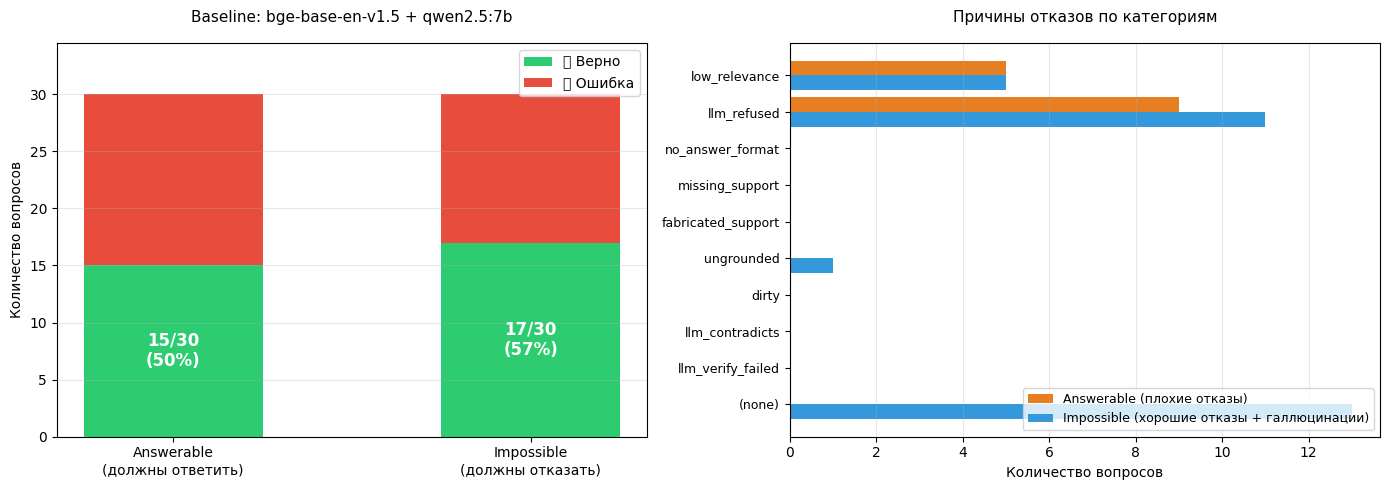


РЕЗУЛЬТАТ BASELINE (n=30 в каждой категории)
  Answerable (дали ответ):  15/30  (50.0%)
  Impossible (отказали):    17/30  (56.7%)
  Средний баланс:           53.3%


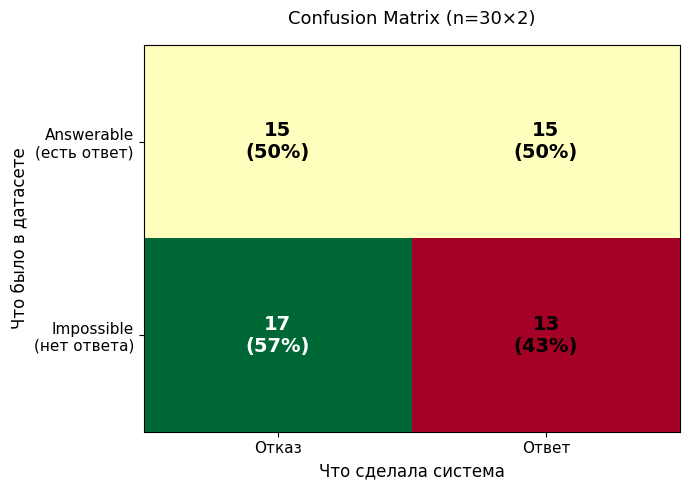


💡 Как читать матрицу:
  Верхняя левая  (15):  ЛОЖНЫЙ ОТКАЗ — плохо (не ответили, хотя могли)
  Верхняя правая (15):  ПРАВИЛЬНО — ответили на answerable ✅
  Нижняя левая   (17):  ПРАВИЛЬНО — отказали на impossible ✅
  Нижняя правая  (13):  ГАЛЛЮЦИНАЦИЯ — плохо (ответили, хотя ответа нет)


In [50]:
import matplotlib.pyplot as plt
import numpy as np
import json
from datetime import datetime
from pathlib import Path
from sklearn.metrics import confusion_matrix, classification_report
from tqdm.auto import tqdm

# ============================================================
# 1. Прогоняем более широкую выборку для честных метрик
# ============================================================
N_EVAL = 30   # было 20; для визуализации 30 нагляднее, но всё ещё быстро (~2 мин)

answerable = [q for q in train_data if not q.get("is_impossible", False)]
impossible = [q for q in train_data if q.get("is_impossible", False)]

print(f"Прогоняем {N_EVAL} answerable + {N_EVAL} impossible...")

results_ans, results_imp = [], []
for item in tqdm(answerable[:N_EVAL], desc="answerable"):
    r = generate_answer(item["question"])
    results_ans.append({
        "question": item["question"][:200],
        "refused": r["refused"],
        "reason": r["refusal_reason"],
        "best_score": r["best_score"],
        "answer": r["answer"][:300],
        "raw": r.get("raw_answer", "")[:300],
    })

for item in tqdm(impossible[:N_EVAL], desc="impossible"):
    r = generate_answer(item["question"])
    results_imp.append({
        "question": item["question"][:200],
        "refused": r["refused"],
        "reason": r["refusal_reason"],
        "best_score": r["best_score"],
        "answer": r["answer"][:300],
        "raw": r.get("raw_answer", "")[:300],
    })

# ============================================================
# 2. Метрики
# ============================================================
# Для answerable: "правильно" = не отказ (система ответила)
# Для impossible: "правильно" = отказ (система не сгаллюцинировала)
tp_ans = sum(1 for r in results_ans if not r["refused"])   # ответил на answerable
tp_imp = sum(1 for r in results_imp if r["refused"])       # отказал на impossible

answerable_rate = tp_ans / N_EVAL * 100
impossible_rate = tp_imp / N_EVAL * 100

# ============================================================
# 3. Визуализация
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# --- График 1: Bar chart по двум категориям ---
ax = axes[0]
categories = ["Answerable\n(должны ответить)", "Impossible\n(должны отказать)"]
correct   = [tp_ans, tp_imp]
incorrect = [N_EVAL - tp_ans, N_EVAL - tp_imp]

x = np.arange(2)
width = 0.5
bars1 = ax.bar(x, correct,   width, label="✅ Верно",  color="#2ecc71")
bars2 = ax.bar(x, incorrect, width, bottom=correct, label="❌ Ошибка", color="#e74c3c")

ax.set_ylabel("Количество вопросов")
ax.set_title(f"Baseline: {EMBEDDER_NAME.split('/')[-1]} + {OLLAMA_MODEL}",
             fontsize=11, pad=15)
ax.set_xticks(x)
ax.set_xticklabels(categories)
ax.set_ylim(0, N_EVAL * 1.15)
ax.legend(loc="upper right")
ax.grid(axis="y", alpha=0.3)

# Подписи процентов на барах
for i, (c, t) in enumerate(zip(correct, [tp_ans, tp_imp])):
    pct = c / N_EVAL * 100
    ax.text(i, c / 2, f"{c}/{N_EVAL}\n({pct:.0f}%)",
            ha="center", va="center", fontweight="bold", color="white", fontsize=12)

# --- График 2: Распределение причин отказов ---
ax = axes[1]
from collections import Counter

# Причины отказов на answerable (плохие отказы)
ans_reasons = Counter(r["reason"] for r in results_ans if r["refused"])
# Причины отказов на impossible (хорошие отказы)
imp_reasons = Counter(r["reason"] for r in results_imp if r["refused"])
# Причины ответов на impossible (плохие ответы — галлюцинации)
imp_answered = sum(1 for r in results_imp if not r["refused"])

# Составляем данные для stacked bar
reason_labels = ["low_relevance", "llm_refused", "no_answer_format",
                 "missing_support", "fabricated_support", "ungrounded",
                 "dirty", "llm_contradicts", "llm_verify_failed", "(none)"]

ans_by_reason = [ans_reasons.get(lbl.split(":")[0], 0) if lbl != "(none)" else 0
                 for lbl in reason_labels]
imp_by_reason = []
for lbl in reason_labels:
    if lbl == "(none)":
        imp_by_reason.append(imp_answered)  # ответы на impossible = галлюцинации
    else:
        # суммируем по префиксу (reason может содержать ":...")
        cnt = sum(v for k, v in imp_reasons.items() if k.split(":")[0] == lbl)
        imp_by_reason.append(cnt)

# Строим stacked horizontal bar
y_pos = np.arange(len(reason_labels))
ax.barh(y_pos - 0.2, ans_by_reason, 0.4, label="Answerable (плохие отказы)",
        color="#e67e22")
ax.barh(y_pos + 0.2, imp_by_reason, 0.4, label="Impossible (хорошие отказы + галлюцинации)",
        color="#3498db")

ax.set_yticks(y_pos)
ax.set_yticklabels([l[:25] for l in reason_labels], fontsize=9)
ax.invert_yaxis()
ax.set_xlabel("Количество вопросов")
ax.set_title("Причины отказов по категориям", fontsize=11, pad=15)
ax.legend(loc="lower right", fontsize=9)
ax.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

# ============================================================
# 4. Текстовый отчёт
# ============================================================
print("\n" + "=" * 70)
print(f"РЕЗУЛЬТАТ BASELINE (n={N_EVAL} в каждой категории)")
print("=" * 70)
print(f"  Answerable (дали ответ):  {tp_ans:2d}/{N_EVAL}  ({answerable_rate:.1f}%)")
print(f"  Impossible (отказали):    {tp_imp:2d}/{N_EVAL}  ({impossible_rate:.1f}%)")
print(f"  Средний баланс:           {(answerable_rate + impossible_rate) / 2:.1f}%")
print("=" * 70)

# ============================================================
# 5. Confusion matrix
# ============================================================
# Строим бинарную матрицу: [answerable_refused, answerable_answered;
#                           impossible_refused, impossible_answered]
cm = np.array([
    [N_EVAL - tp_ans, tp_ans],     # answerable: [refused, answered]
    [tp_imp, N_EVAL - tp_imp],      # impossible: [refused, answered]
])

fig, ax = plt.subplots(figsize=(7, 5))
im = ax.imshow(cm, cmap="RdYlGn", aspect="auto")
ax.set_xticks([0, 1])
ax.set_yticks([0, 1])
ax.set_xticklabels(["Отказ", "Ответ"], fontsize=11)
ax.set_yticklabels(["Answerable\n(есть ответ)", "Impossible\n(нет ответа)"], fontsize=11)
ax.set_xlabel("Что сделала система", fontsize=12)
ax.set_ylabel("Что было в датасете", fontsize=12)
ax.set_title(f"Confusion Matrix (n={N_EVAL}×2)", fontsize=13, pad=15)

# Подписи в ячейках
for i in range(2):
    for j in range(2):
        val = cm[i, j]
        pct = val / N_EVAL * 100
        color = "white" if val > N_EVAL * 0.5 else "black"
        ax.text(j, i, f"{val}\n({pct:.0f}%)",
                ha="center", va="center", fontsize=14, fontweight="bold", color=color)

plt.tight_layout()
plt.show()

# Интерпретация
print("\n💡 Как читать матрицу:")
print(f"  Верхняя левая  ({cm[0,0]}):  ЛОЖНЫЙ ОТКАЗ — плохо (не ответили, хотя могли)")
print(f"  Верхняя правая ({cm[0,1]}):  ПРАВИЛЬНО — ответили на answerable ✅")
print(f"  Нижняя левая   ({cm[1,0]}):  ПРАВИЛЬНО — отказали на impossible ✅")
print(f"  Нижняя правая  ({cm[1,1]}):  ГАЛЛЮЦИНАЦИЯ — плохо (ответили, хотя ответа нет)")

In [51]:
import json
from datetime import datetime
from pathlib import Path

def save_snapshot(results_ans, results_imp, tag: str):
    """Сохраняет снапшот метрик и результатов для последующего сравнения."""
    Path("snapshots").mkdir(exist_ok=True)

    tp_ans = sum(1 for r in results_ans if not r["refused"])
    tp_imp = sum(1 for r in results_imp if r["refused"])

    snapshot = {
        "tag": tag,
        "timestamp": datetime.now().isoformat(),
        "config": {
            "embedder": EMBEDDER_NAME,
            "llm": OLLAMA_MODEL,
            "nli_model": NLI_MODEL_NAME,
            "sim_threshold": SIM_THRESHOLD,
            "top_k": TOP_K,
            "chunk_size": CHUNK_SIZE,
            "refusal_phrase": REFUSAL_PHRASE[:80],
        },
        "metrics": {
            "n_answerable": len(results_ans),
            "n_impossible": len(results_imp),
            "answerable_correct": tp_ans,
            "impossible_correct": tp_imp,
            "answerable_rate": tp_ans / len(results_ans) * 100,
            "impossible_rate": tp_imp / len(results_imp) * 100,
            "balanced_avg": (tp_ans / len(results_ans) + tp_imp / len(results_imp)) / 2 * 100,
        },
        "results_answerable": results_ans,
        "results_impossible": results_imp,
    }

    filename = f"snapshots/{tag}_{datetime.now().strftime('%Y%m%d_%H%M%S')}.json"
    with open(filename, "w", encoding="utf-8") as f:
        json.dump(snapshot, f, ensure_ascii=False, indent=2)
    print(f"💾 Снапшот сохранён: {filename}")
    return filename


# Сохраняем ТЕКУЩИЙ baseline
nli_large_file = save_snapshot(results_ans, results_imp, tag="nli_large")

print(f"\n📁 Файл: {nli_large_file}")
print(f"📊 Answerable: {sum(1 for r in results_ans if not r['refused'])}/{len(results_ans)}")
print(f"📊 Impossible: {sum(1 for r in results_imp if r['refused'])}/{len(results_imp)}")

💾 Снапшот сохранён: snapshots/nli_large_20261028_081829.json

📁 Файл: snapshots/nli_large_20261028_081829.json
📊 Answerable: 15/30
📊 Impossible: 17/30


In [52]:
def compare_snapshots(file_a: str, file_b: str):
    """Сравнивает два снапшота side-by-side."""
    with open(file_a, "r", encoding="utf-8") as f:
        a = json.load(f)
    with open(file_b, "r", encoding="utf-8") as f:
        b = json.load(f)

    print("=" * 70)
    print(f"{'Метрика':<30} {a['tag']:<18} {b['tag']:<18} {'Δ':>8}")
    print("=" * 70)

    def fmt_row(name, va, vb, unit=""):
        delta = vb - va
        sign = "+" if delta > 0 else ""
        print(f"{name:<30} {va:>10.1f}{unit:<8} {vb:>10.1f}{unit:<8} {sign}{delta:>7.1f}")

    fmt_row("Answerable (correct)", a["metrics"]["answerable_correct"],
            b["metrics"]["answerable_correct"])
    fmt_row("Answerable (%)", a["metrics"]["answerable_rate"],
            b["metrics"]["answerable_rate"], "%")
    fmt_row("Impossible (correct)", a["metrics"]["impossible_correct"],
            b["metrics"]["impossible_correct"])
    fmt_row("Impossible (%)", a["metrics"]["impossible_rate"],
            b["metrics"]["impossible_rate"], "%")
    fmt_row("Balanced avg (%)", a["metrics"]["balanced_avg"],
            b["metrics"]["balanced_avg"], "%")

    print("=" * 70)

    # Конфиги
    print("\n📋 Конфиги:")
    for key in a["config"]:
        va, vb = a["config"][key], b["config"].get(key)
        marker = " ⚠️" if va != vb else ""
        print(f"  {key:<20} {str(va):<30} → {str(vb)}{marker}")

compare_snapshots(baseline_file, nli_large_file)

Метрика                        baseline_nli_base  nli_large                 Δ
Answerable (correct)                 16.0               15.0            -1.0
Answerable (%)                       53.3%              50.0%           -3.3
Impossible (correct)                 16.0               17.0         +    1.0
Impossible (%)                       53.3%              56.7%        +    3.3
Balanced avg (%)                     53.3%              53.3%            0.0

📋 Конфиги:
  embedder             BAAI/bge-base-en-v1.5          → BAAI/bge-base-en-v1.5
  llm                  qwen2.5:7b                     → qwen2.5:7b
  nli_model            cross-encoder/nli-deberta-v3-base → cross-encoder/nli-deberta-v3-large ⚠️
  sim_threshold        0.75                           → 0.75
  top_k                10                             → 10
  chunk_size           1000                           → 1000
  refusal_phrase       I cannot answer this question because the provided documents do not contain t

In [53]:
import re
import numpy as np
import pickle
import time
from pathlib import Path
from tqdm.auto import tqdm

# ----------------------------------------------------------------
# Имена признаков (для интерпретации модели)
# ----------------------------------------------------------------
FEATURE_NAMES = [
    "best_score", "gap_1_2", "score_3", "score_5", "score_10",
    "mean_score", "std_score", "n_above_0.85", "n_above_0.90",
    "lex_overlap_top1", "max_lex_overlap_top5",
    "q_len_norm", "q_has_version", "q_has_error_code",
    "q_is_howto", "q_is_what_why", "q_has_question_mark",
]


def extract_features(query: str, scores: np.ndarray, idxs: np.ndarray) -> list:
    """
    Извлекает признаки из retrieval-результатов.
    Используется и при обучении, и при инференсе — логика должна быть идентичной.
    """
    top_scores = scores.tolist()
    top1_chunk = all_chunks[idxs[0]]

    # Лексическое пересечение слов запроса и top-1 / top-5 чанков
    q_words = {w.lower() for w in re.findall(r'\w+', query) if len(w) > 3}

    c1_words = {w.lower() for w in re.findall(r'\w+', top1_chunk) if len(w) > 3}
    lex_overlap_top1 = (len(q_words & c1_words) / max(len(q_words), 1)) if q_words else 0.0

    overlaps_top5 = []
    for i in range(min(5, len(idxs))):
        c_words = {w.lower() for w in re.findall(r'\w+', all_chunks[idxs[i]]) if len(w) > 3}
        overlaps_top5.append((len(q_words & c_words) / max(len(q_words), 1)) if q_words else 0.0)
    max_lex_overlap_top5 = max(overlaps_top5) if overlaps_top5 else 0.0

    q_lower = query.lower()

    return [
        top_scores[0],                                              # best_score
        top_scores[1] - top_scores[0],                              # gap_1_2
        top_scores[2] if len(top_scores) > 2 else top_scores[-1],    # score_3
        top_scores[4] if len(top_scores) > 4 else top_scores[-1],    # score_5
        top_scores[9] if len(top_scores) > 9 else top_scores[-1],    # score_10
        float(np.mean(top_scores)),                                 # mean_score
        float(np.std(top_scores)),                                  # std_score
        sum(1 for s in top_scores if s > 0.85),                     # n_above_0.85
        sum(1 for s in top_scores if s > 0.90),                     # n_above_0.90
        lex_overlap_top1,                                           # lex_overlap_top1
        max_lex_overlap_top5,                                       # max_lex_overlap_top5
        len(query.split()) / 20,                                    # q_len_norm
        int(bool(re.search(r'\d+\.\d+', query))),                   # q_has_version
        int(bool(re.search(r'[A-Z]{2,}\d+', query))),                # q_has_error_code
        int(q_lower.startswith(("how ", "how to ", "how do", "how can"))),  # q_is_howto
        int(q_lower.startswith(("what ", "why ", "when "))),         # q_is_what_why
        int('?' in query),                                           # q_has_question_mark
    ]


# ----------------------------------------------------------------
# retrieve_full: один проход = retrieval + признаки
# ----------------------------------------------------------------
def retrieve_full(query: str, top_k: int = 15,
                  threshold: float = SIM_THRESHOLD,
                  keep_ratio: float = KEEP_RATIO,
                  max_chars: int = MAX_CONTEXT_CHARS):
    """Возвращает (chunks, meta, best_score, features). Features нужны для классификатора."""
    q_emb = embedder.encode([f"query: {query}"], normalize_embeddings=True,
                            convert_to_numpy=True).astype("float32")
    scores, idxs = index.search(q_emb, top_k)
    scores, idxs = scores[0], idxs[0]

    feats = extract_features(query, scores, idxs)
    best = float(scores[0])

    if best < threshold:
        return None, None, best, feats

    kept_chunks, kept_meta, total = [], [], 0
    for score, idx in zip(scores, idxs):
        if score < best * keep_ratio:
            continue
        c = all_chunks[idx]
        if total + len(c) > max_chars and kept_chunks:
            break
        kept_chunks.append(c)
        kept_meta.append(chunk_metadata[idx])
        total += len(c)

    return kept_chunks, kept_meta, best, feats


# ----------------------------------------------------------------
# Сбор обучающей выборки (~5 мин)
# ----------------------------------------------------------------
FEAT_CACHE = Path("train_features.pkl")

if FEAT_CACHE.exists():
    print(f"📂 Загружаем признаки из кэша {FEAT_CACHE}...")
    with open(FEAT_CACHE, "rb") as f:
        cached = pickle.load(f)
    X_train = cached["X"]
    y_train = cached["y"]
    print(f"✅ Загружено: X={X_train.shape}, y={y_train.shape}")
else:
    print(f"Собираем признаки для {len(train_data)} вопросов (~5 мин)...")
    X_list, y_list = [], []
    t0 = time.time()
    for item in tqdm(train_data, desc="extracting"):
        q = item["question"]
        try:
            _, _, _, feats = retrieve_full(q, threshold=0.0)  # без порога — нужны все признаки
            X_list.append(feats)
            y_list.append(1 if item.get("is_impossible", False) else 0)
        except Exception as e:
            print(f"⚠️ Пропуск {q[:60]}: {e}")
            continue

    X_train = np.array(X_list, dtype=np.float32)
    y_train = np.array(y_list, dtype=np.int32)
    elapsed = time.time() - t0
    print(f"✅ Собрано за {elapsed/60:.1f} мин: X={X_train.shape}, "
          f"impossible={y_train.sum()}/{len(y_train)}")

    with open(FEAT_CACHE, "wb") as f:
        pickle.dump({"X": X_train, "y": y_train}, f)
    print(f"💾 Кэш сохранён в {FEAT_CACHE}")

Собираем признаки для 910 вопросов (~5 мин)...


extracting:   0%|          | 0/910 [00:00<?, ?it/s]

✅ Собрано за 1.4 мин: X=(910, 17), impossible=300/910
💾 Кэш сохранён в train_features.pkl


In [54]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold, cross_val_predict, cross_val_score
from sklearn.metrics import f1_score, roc_auc_score, confusion_matrix, classification_report

# ----------------------------------------------------------------
# 1. Нормализация
# ----------------------------------------------------------------
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_train)

# ----------------------------------------------------------------
# 2. Обучение с balanced class weights (300 vs 610 — есть дисбаланс)
# ----------------------------------------------------------------
clf = LogisticRegression(
    C=1.0,
    class_weight="balanced",
    max_iter=3000,
    random_state=42,
)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# CV-метрики
f1_scores = cross_val_score(clf, X_scaled, y_train, cv=cv, scoring="f1")
auc_scores = cross_val_score(clf, X_scaled, y_train, cv=cv, scoring="roc_auc")

print(f"{'='*60}")
print(f"CV F1  на is_impossible: {f1_scores.mean():.3f} ± {f1_scores.std():.3f}")
print(f"CV AUC на is_impossible: {auc_scores.mean():.3f} ± {auc_scores.std():.3f}")
print(f"{'='*60}")

# ----------------------------------------------------------------
# 3. OOF-предсказания для подбора порога
# ----------------------------------------------------------------
oof_proba = cross_val_predict(clf, X_scaled, y_train, cv=cv,
                              method="predict_proba")[:, 1]

best_th, best_f1 = 0.5, 0.0
rows = []
for th in np.arange(0.30, 0.80, 0.02):
    preds = (oof_proba > th).astype(int)
    f1 = f1_score(y_train, preds, zero_division=0)
    rows.append((th, f1))
    if f1 > best_f1:
        best_f1, best_th = f1, th

print(f"\nЛучший порог на OOF: {best_th:.2f} (F1={best_f1:.3f})")
print(f"\nПорог  F1")
for th, f1 in rows[::5]:  # каждый 5-й для компактности
    print(f"  {th:.2f}  {f1:.3f}")

# ----------------------------------------------------------------
# 4. Финальное обучение на всех данных
# ----------------------------------------------------------------
clf.fit(X_scaled, y_train)
print(f"\n✅ Классификатор обучен на {len(X_train)} примерах")

# ----------------------------------------------------------------
# 5. Важность признаков
# ----------------------------------------------------------------
print(f"\n{'='*60}\nВажность признаков (|coef|):\n{'='*60}")
importances = list(zip(FEATURE_NAMES, clf.coef_[0]))
for name, coef in sorted(importances, key=lambda x: abs(x[1]), reverse=True):
    bar = "█" * int(abs(coef) * 20)
    sign = "+" if coef > 0 else "-"
    print(f"  {name:22s} {sign}{abs(coef):.3f}  {bar}")
print("\n(+) → выше P(impossible); (−) → ниже P(impossible)")

CV F1  на is_impossible: 0.463 ± 0.040
CV AUC на is_impossible: 0.602 ± 0.032

Лучший порог на OOF: 0.32 (F1=0.511)

Порог  F1
  0.30  0.509
  0.40  0.495
  0.50  0.466
  0.60  0.323
  0.70  0.125

✅ Классификатор обучен на 910 примерах

Важность признаков (|coef|):
  score_3                +0.656  █████████████
  std_score              -0.411  ████████
  best_score             -0.377  ███████
  n_above_0.85           -0.303  ██████
  gap_1_2                -0.258  █████
  max_lex_overlap_top5   -0.159  ███
  q_has_error_code       +0.154  ███
  score_5                +0.138  ██
  q_has_version          -0.116  ██
  q_has_question_mark    +0.080  █
  score_10               -0.077  █
  q_is_what_why          +0.042  
  q_len_norm             -0.031  
  q_is_howto             -0.022  
  n_above_0.90           +0.009  
  lex_overlap_top1       +0.005  
  mean_score             -0.004  

(+) → выше P(impossible); (−) → ниже P(impossible)


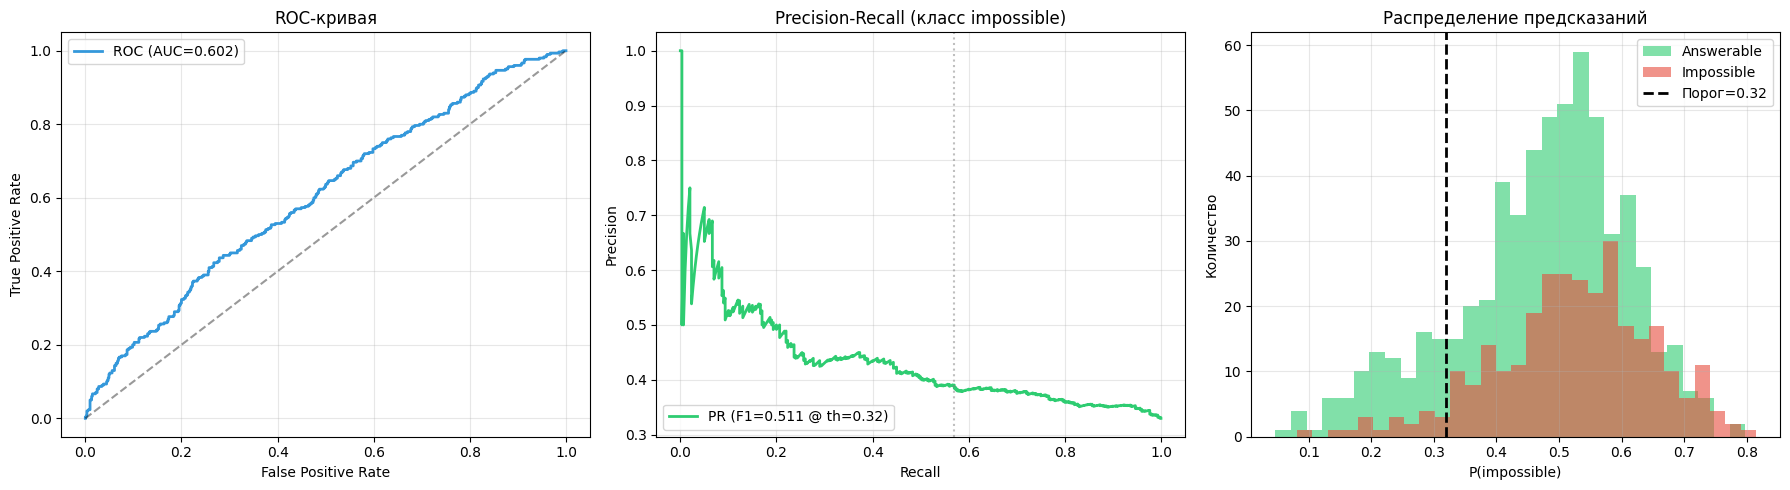


Confusion matrix при th=0.32:
                 Предсказано
               Answer  Imposs
  Answerable      92     518
  Impossible      19     281


In [55]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, precision_recall_curve, auc

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# --- ROC ---
fpr, tpr, _ = roc_curve(y_train, oof_proba)
roc_auc = auc(fpr, tpr)
ax = axes[0]
ax.plot(fpr, tpr, color="#3498db", lw=2, label=f"ROC (AUC={roc_auc:.3f})")
ax.plot([0, 1], [0, 1], "k--", alpha=0.4)
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_title("ROC-кривая")
ax.legend()
ax.grid(alpha=0.3)

# --- Precision-Recall ---
prec, rec, _ = precision_recall_curve(y_train, oof_proba)
ax = axes[1]
ax.plot(rec, prec, color="#2ecc71", lw=2, label=f"PR (F1={best_f1:.3f} @ th={best_th:.2f})")
ax.axvline(rec.mean(), color="gray", ls=":", alpha=0.5)
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title("Precision-Recall (класс impossible)")
ax.legend()
ax.grid(alpha=0.3)

# --- Распределение p_impossible ---
ax = axes[2]
ax.hist(oof_proba[y_train == 0], bins=30, alpha=0.6, label="Answerable", color="#2ecc71")
ax.hist(oof_proba[y_train == 1], bins=30, alpha=0.6, label="Impossible", color="#e74c3c")
ax.axvline(best_th, color="black", ls="--", lw=2, label=f"Порог={best_th:.2f}")
ax.set_xlabel("P(impossible)")
ax.set_ylabel("Количество")
ax.set_title("Распределение предсказаний")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Confusion matrix при выбранном пороге
preds = (oof_proba > best_th).astype(int)
cm = confusion_matrix(y_train, preds)
print(f"\nConfusion matrix при th={best_th:.2f}:")
print(f"                 Предсказано")
print(f"               Answer  Imposs")
print(f"  Answerable  {cm[0,0]:>6d}  {cm[0,1]:>6d}")
print(f"  Impossible  {cm[1,0]:>6d}  {cm[1,1]:>6d}")

In [56]:
# Порог, подобранный на OOF
CLF_IMPOSSIBLE_TH = float(best_th)   # например, 0.55 или 0.60

def generate_answer_v3_backup(query: str, debug: bool = False) -> dict:
    """
    Трёхуровневая защита:
      1. Классификатор is_impossible — если P > CLF_IMPOSSIBLE_TH → отказ БЕЗ LLM
      2. LLM + промпт с обязательной цитатой
      3. Clean + NLI (contradiction против контекста)
    """
    # 1. Retrieval + признаки
    chunks, meta, best_score, feats = retrieve_full(query)

    if chunks is None:
        return {**_refusal_result(best_score, [], "low_relevance"),
                "p_impossible": None}

    # 2. Классификатор
    feats_scaled = scaler.transform([feats])
    p_impossible = float(clf.predict_proba(feats_scaled)[0][1])

    if debug:
        print(f"  P(impossible) = {p_impossible:.3f}  (порог {CLF_IMPOSSIBLE_TH:.2f})")

    if p_impossible > CLF_IMPOSSIBLE_TH:
        return {**_refusal_result(best_score, meta,
                                  f"clf_impossible(p={p_impossible:.2f})"),
                "p_impossible": p_impossible}

    # 3. LLM с обычным промптом
    context = "\n\n---\n\n".join(chunks)
    prompt = _build_prompt(query, context)

    try:
        raw = llm.invoke(prompt).content.strip()
    except Exception as e:
        return {"answer": f"[LLM error: {e}]", "refused": False,
                "best_score": best_score, "sources": meta,
                "refusal_reason": "llm_error", "raw_answer": "",
                "p_impossible": p_impossible}

    if debug:
        print(f"  RAW: {raw[:200]}")

    if _looks_like_refusal(raw):
        return {**_refusal_result(best_score, meta, "llm_refused", raw),
                "p_impossible": p_impossible}

    if "ANSWER:" not in raw:
        return {**_refusal_result(best_score, meta, "no_answer_format", raw),
                "p_impossible": p_impossible}

    parts = raw.split("ANSWER:", 1)
    pre, answer = parts[0], parts[1].strip()
    support = pre.split("SUPPORT:", 1)[1].strip() if "SUPPORT:" in pre else ""

    if not support:
        return {**_refusal_result(best_score, meta, "missing_support", raw),
                "p_impossible": p_impossible}

    if not _support_is_in_context(support, context):
        return {**_refusal_result(best_score, meta, "fabricated_support", raw),
                "p_impossible": p_impossible}

    answer = dedupe_repeated_lines(strip_markdown(answer))
    if _looks_like_refusal(answer):
        return {**_refusal_result(best_score, meta, "llm_refused", raw),
                "p_impossible": p_impossible}

    ok, reason = answer_is_clean(answer)
    if not ok:
        return {**_refusal_result(best_score, meta, f"dirty:{reason}", raw),
                "p_impossible": p_impossible}

    ok, reason = answer_is_grounded_nli(answer, support, context=context, debug=debug)
    if not ok:
        return {**_refusal_result(best_score, meta, f"ungrounded:{reason}", raw),
                "p_impossible": p_impossible}

    return {
        "answer": answer, "refused": False,
        "best_score": best_score, "sources": meta,
        "refusal_reason": "", "raw_answer": raw,
        "support": support,
        "p_impossible": p_impossible,
    }

print(f"✅ generate_answer_v3 готов. Порог классификатора: {CLF_IMPOSSIBLE_TH:.2f}")

✅ generate_answer_v3 готов. Порог классификатора: 0.32


In [59]:
def evaluate_v3(n: int = 30, tag: str = "nli_base_clf"):
    answerable = [q for q in train_data if not q.get("is_impossible", False)]
    impossible = [q for q in train_data if q.get("is_impossible", False)]

    results_ans, results_imp = [], []

    print(f"Прогоняем {n} answerable...")
    for item in tqdm(answerable[:n], desc="answerable"):
        r = generate_answer_v3(item["question"])
        results_ans.append({
            "question": item["question"][:200],
            "refused": r["refused"],
            "reason": r["refusal_reason"],
            "best_score": r["best_score"],
            "p_impossible": r.get("p_impossible"),
            "answer": r["answer"][:300],
        })

    print(f"Прогоняем {n} impossible...")
    for item in tqdm(impossible[:n], desc="impossible"):
        r = generate_answer_v3(item["question"])
        results_imp.append({
            "question": item["question"][:200],
            "refused": r["refused"],
            "reason": r["refusal_reason"],
            "best_score": r["best_score"],
            "p_impossible": r.get("p_impossible"),
            "answer": r["answer"][:300],
        })

    tp_ans = sum(1 for r in results_ans if not r["refused"])
    tp_imp = sum(1 for r in results_imp if r["refused"])

    print(f"\n{'='*60}")
    print(f"РЕЗУЛЬТАТ v3 (classifier-augmented), n={n}")
    print(f"{'='*60}")
    print(f"  Answerable (дали ответ):  {tp_ans:2d}/{n}  ({tp_ans/n*100:.1f}%)")
    print(f"  Impossible (отказали):    {tp_imp:2d}/{n}  ({tp_imp/n*100:.1f}%)")
    print(f"  Balanced avg:             {(tp_ans + tp_imp) / (2*n) * 100:.1f}%")
    print(f"{'='*60}")

    # Распределение причин
    from collections import Counter
    print("\nПричины отказов на answerable:")
    for r, c in Counter(x["reason"] for x in results_ans if x["refused"]).most_common():
        print(f"  {r:40s} {c}")
    print("\nПричины отказов на impossible:")
    for r, c in Counter(x["reason"] for x in results_imp if x["refused"]).most_common():
        print(f"  {r:40s} {c}")

    # Сохраняем снапшот
    file = save_snapshot(results_ans, results_imp, tag=tag)
    return file


v3_file = evaluate_v3(n=30, tag="nli_base_clf")

# Сравнение с baseline (файл из предыдущего запуска)
if Path("snapshots").exists():
    snapshots = sorted(Path("snapshots").glob("baseline_*.json"))
    if snapshots:
        print("\n" + "=" * 70)
        print("СРАВНЕНИЕ С BASELINE")
        print("=" * 70)
        compare_snapshots(str(snapshots[-1]), v3_file)

Прогоняем 30 answerable...


answerable:   0%|          | 0/30 [00:00<?, ?it/s]

Прогоняем 30 impossible...


impossible:   0%|          | 0/30 [00:00<?, ?it/s]


РЕЗУЛЬТАТ v3 (classifier-augmented), n=30
  Answerable (дали ответ):   3/30  (10.0%)
  Impossible (отказали):    30/30  (100.0%)
  Balanced avg:             55.0%

Причины отказов на answerable:
  clf_impossible(p=0.56)                   4
  clf_impossible(p=0.69)                   2
  low_relevance                            2
  clf_impossible(p=0.59)                   2
  clf_impossible(p=0.45)                   2
  clf_impossible(p=0.72)                   1
  clf_impossible(p=0.38)                   1
  clf_impossible(p=0.49)                   1
  clf_impossible(p=0.62)                   1
  clf_impossible(p=0.34)                   1
  ungrounded:1/2 предложений противоречат контексту 1
  clf_impossible(p=0.36)                   1
  clf_impossible(p=0.37)                   1
  clf_impossible(p=0.50)                   1
  clf_impossible(p=0.53)                   1
  clf_impossible(p=0.55)                   1
  clf_impossible(p=0.60)                   1
  clf_impossible(p=0.44)      

In [60]:
# Сохраняем классификатор + scaler, чтобы не переобучать при перезапуске Colab
MODEL_PATH = Path("impossible_classifier.pkl")
with open(MODEL_PATH, "wb") as f:
    pickle.dump({
        "clf": clf,
        "scaler": scaler,
        "best_threshold": CLF_IMPOSSIBLE_TH,
        "feature_names": FEATURE_NAMES,
        "cv_f1": f1_scores.mean(),
        "cv_auc": auc_scores.mean(),
    }, f)
print(f"💾 Модель сохранена: {MODEL_PATH}")

# Копируем всё важное в Google Drive (если подключен)
try:
    from google.colab import drive
    drive.mount('/content/drive', force_remount=False)
    target = Path("/content/drive/MyDrive/techqa_saved")
    target.mkdir(exist_ok=True)
    import shutil
    for f in [MODEL_PATH, Path("train_features.pkl"),
              Path("techqa_chunk_embeddings_bge_base.pkl")]:
        if f.exists():
            shutil.copy(f, target / f.name)
            print(f"  📤 {f.name} → Google Drive")
    for f in Path("snapshots").glob("*.json"):
        shutil.copy(f, target / f.name)
    print(f"✅ Всё сохранено в {target}")
except Exception as e:
    print(f"⚠️ Google Drive не подключён: {e}")
    print("   Модель остаётся локально; при перезапуске Colab её нужно будет переобучить (~30 сек).")

💾 Модель сохранена: impossible_classifier.pkl
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
  📤 impossible_classifier.pkl → Google Drive
  📤 train_features.pkl → Google Drive
  📤 techqa_chunk_embeddings_bge_base.pkl → Google Drive
✅ Всё сохранено в /content/drive/MyDrive/techqa_saved


In [69]:
import pickle, time, re, json
import numpy as np
from pathlib import Path
from tqdm.auto import tqdm

# ----------------------------------------------------------------
# 1. Holdout: последние 30 из каждого класса — НИКОГДА не попадут в обучение
# ----------------------------------------------------------------
answerable_all = [q for q in train_data if not q.get("is_impossible", False)]
impossible_all = [q for q in train_data if q.get("is_impossible", False)]

HOLDOUT_N = 30
holdout   = answerable_all[-HOLDOUT_N:] + impossible_all[-HOLDOUT_N:]
training  = answerable_all[:-HOLDOUT_N] + impossible_all[:-HOLDOUT_N]

n_ans_tr = len(answerable_all) - HOLDOUT_N
n_imp_tr = len(impossible_all) - HOLDOUT_N

print(f"Training: {len(training)}  (answerable={n_ans_tr}, impossible={n_imp_tr})")
print(f"Holdout : {len(holdout)}  (для честной финальной оценки)")

# ----------------------------------------------------------------
# 2. Сбор (question, top1_chunk, label) пар
# ----------------------------------------------------------------
PAIRS_CACHE = Path("clf_pairs.pkl")

if PAIRS_CACHE.exists():
    print(f"📂 Загружаем пары из {PAIRS_CACHE}...")
    with open(PAIRS_CACHE, "rb") as f:
        cached = pickle.load(f)
    pairs_train = cached["pairs"]
    print(f"✅ Загружено {len(pairs_train)} пар")
else:
    print(f"Собираем пары для {len(training)} вопросов (~3–5 мин)...")
    pairs_train = []
    skipped = 0
    t0 = time.time()

    for item in tqdm(training, desc="building pairs"):
        q = item["question"]
        # Используем retrieve (возвращает chunks, meta, best_score)
        chunks, meta, best = retrieve(q)
        if chunks is None:
            # low_relevance — эти кейсы отсекаются guardrail #1, в обучение не идут
            skipped += 1
            continue
        pairs_train.append({
            "question":   q,
            "top1_chunk": chunks[0],
            "label":      int(item.get("is_impossible", False)),
        })

    elapsed = (time.time() - t0) / 60
    print(f"✅ Собрано за {elapsed:.1f} мин: {len(pairs_train)} пар, "
          f"пропущено {skipped} (low_relevance)")

    n_pos = sum(p["label"] for p in pairs_train)
    print(f"   answerable: {len(pairs_train) - n_pos}")
    print(f"   impossible: {n_pos}")

    with open(PAIRS_CACHE, "wb") as f:
        pickle.dump({"pairs": pairs_train, "holdout": holdout}, f)
    print(f"💾 Сохранено в {PAIRS_CACHE}")

Training: 850  (answerable=580, impossible=270)
Holdout : 60  (для честной финальной оценки)
📂 Загружаем пары из clf_pairs.pkl...
✅ Загружено 789 пар


In [70]:
#!pip install -q sentencepiece

from transformers import AutoTokenizer
from datasets import Dataset
from sklearn.model_selection import train_test_split

# ⚠️ NLI-модель вместо distilbert
MODEL_NAME = "cross-encoder/nli-deberta-v3-small"
MAX_LEN    = 512

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

ds_full = Dataset.from_dict({
    "question": [p["question"]   for p in pairs_train],
    "chunk":    [p["top1_chunk"] for p in pairs_train],
    "label":    [p["label"]      for p in pairs_train],
})

labels_list = [p["label"] for p in pairs_train]
idx_tr, idx_val = train_test_split(
    np.arange(len(pairs_train)),
    test_size=0.15, stratify=labels_list, random_state=42,
)

ds_train = ds_full.select(idx_tr.tolist())
ds_val   = ds_full.select(idx_val.tolist())

def tokenize_fn(batch):
    return tokenizer(
        batch["question"], batch["chunk"],
        truncation=True, max_length=MAX_LEN, padding=False,
    )

ds_train = ds_train.map(tokenize_fn, batched=True)
ds_val   = ds_val.map(tokenize_fn,   batched=True)

print(f"Train: {len(ds_train)}  Val: {len(ds_val)}")
print(f"Train balance: answerable={sum(1 for i in idx_tr if labels_list[i]==0)}, "
      f"impossible={sum(1 for i in idx_tr if labels_list[i]==1)}")

config.json:   0%|          | 0.00/1.05k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/1.35k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/8.66M [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/301 [00:00<?, ?B/s]

Map:   0%|          | 0/670 [00:00<?, ? examples/s]

Map:   0%|          | 0/119 [00:00<?, ? examples/s]

Train: 670  Val: 119
Train balance: answerable=458, impossible=212


In [71]:
import inspect
import torch
import transformers
from transformers import (
    AutoModelForSequenceClassification,
    TrainingArguments, DataCollatorWithPadding,
)
from sklearn.metrics import f1_score, accuracy_score, roc_auc_score

print(f"transformers: {transformers.__version__}")

# ----------------------------------------------------------------
# 1. Модель (переинициализируем голову на 2 класса)
# ----------------------------------------------------------------
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME, num_labels=2, ignore_mismatched_sizes=True,
)

# ----------------------------------------------------------------
# 2. Веса классов: [answerable, impossible]
#    answerable ~580, impossible ~230 → вес обратно пропорционален
# ----------------------------------------------------------------
n_ans = sum(1 for i in idx_tr if labels_list[i] == 0)
n_imp = sum(1 for i in idx_tr if labels_list[i] == 1)
total = n_ans + n_imp
w_ans = total / (2 * n_ans)
w_imp = total / (2 * n_imp)
CLASS_WEIGHTS = torch.tensor([w_ans, w_imp], dtype=torch.float32)
print(f"Class weights: answerable={w_ans:.2f}, impossible={w_imp:.2f}")

# ----------------------------------------------------------------
# 3. Кастомный Trainer с взвешенным loss
# ----------------------------------------------------------------
from transformers import Trainer

class WeightedTrainer(Trainer):
    def __init__(self, class_weights=None, *args, **kwargs):
        super().__init__(*args, **kwargs)
        self.class_weights = class_weights

    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.pop("labels")
        outputs = model(**inputs)
        logits = outputs.logits
        loss = torch.nn.functional.cross_entropy(
            logits, labels,
            weight=self.class_weights.to(logits.device) if self.class_weights is not None else None,
        )
        return (loss, outputs) if return_outputs else loss

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    probs = torch.softmax(torch.tensor(logits), dim=-1).numpy()[:, 1]
    preds = (probs > 0.5).astype(int)
    return {
        "f1":       f1_score(labels, preds),
        "accuracy": accuracy_score(labels, preds),
        "auc":      roc_auc_score(labels, probs),
    }

# ----------------------------------------------------------------
# 4. TrainingArguments (авто-детект API — как в прошлый раз)
# ----------------------------------------------------------------
arg_names = inspect.signature(TrainingArguments.__init__).parameters

base_kwargs = dict(
    output_dir="clf_impossible_v2",
    num_train_epochs=8,                        # ⚠️ больше эпох
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    learning_rate=3e-5,                        # ⚠️ чуть выше
    weight_decay=0.01,
    save_strategy="epoch",
    save_total_limit=2,
    load_best_model_at_end=True,
    metric_for_best_model="auc",               # ⚠️ AUC вместо F1
    greater_is_better=True,
    fp16=True,
    logging_steps=20,
    report_to="none",
    seed=42,
)

if "eval_strategy" in arg_names:
    base_kwargs["eval_strategy"] = "epoch"
elif "evaluation_strategy" in arg_names:
    base_kwargs["evaluation_strategy"] = "epoch"

if "warmup_ratio" in arg_names:
    base_kwargs["warmup_ratio"] = 0.1
else:
    base_kwargs["warmup_steps"] = 30

args = TrainingArguments(**base_kwargs)

# ----------------------------------------------------------------
# 5. Trainer
# ----------------------------------------------------------------
trainer_params = inspect.signature(Trainer.__init__).parameters

trainer_kwargs = dict(
    model=model, args=args,
    train_dataset=ds_train, eval_dataset=ds_val,
    data_collator=DataCollatorWithPadding(tokenizer=tokenizer),
    compute_metrics=compute_metrics,
    class_weights=CLASS_WEIGHTS,             # ⚠️ взвешенный loss
)
if "processing_class" in trainer_params:
    trainer_kwargs["processing_class"] = tokenizer
elif "tokenizer" in trainer_params:
    trainer_kwargs["tokenizer"] = tokenizer

trainer = WeightedTrainer(**trainer_kwargs)

# ----------------------------------------------------------------
# 6. Обучение
# ----------------------------------------------------------------
print("\n🚀 Старт обучения...")
trainer.train()
print("✅ Обучение завершено")

transformers: 5.20.2


[transformers] You passed `num_labels=2` which is incompatible to the `id2label` map of length `3`.


model.safetensors: reconstructing file:   0%|          |  0.00B /  568MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/106 [00:00<?, ?it/s]

...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

✅ Обучение завершено


p_impossible stats:
  min=0.015  max=0.861  mean=0.365  std=0.326
  Answerable: mean=0.342, std=0.318
  Impossible: mean=0.415, std=0.337

✅ std > 0.05 — модель различает классы

Best threshold=0.64  F1=0.439

Confusion matrix при th=0.64:
                  Answer  Imposs
  Answerable        55       26
  Impossible        20       18


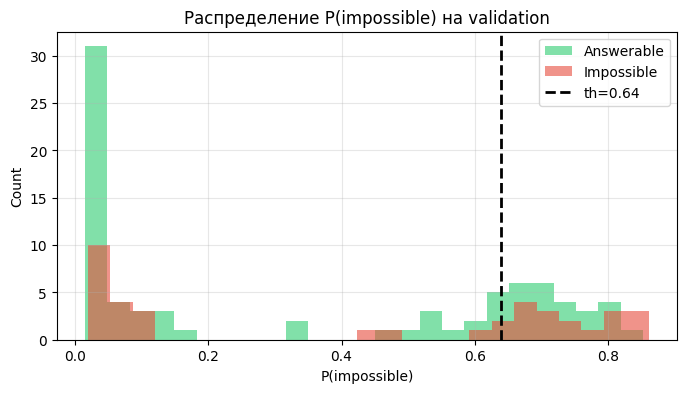

In [72]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, roc_curve, auc, precision_recall_curve

val_pred = trainer.predict(ds_val)
val_probs = torch.softmax(torch.tensor(val_pred.predictions), dim=-1).numpy()[:, 1]
val_labels = val_pred.label_ids

# ⚠️ КРИТИЧЕСКАЯ ПРОВЕРКА: распределение p_impossible
print(f"p_impossible stats:")
print(f"  min={val_probs.min():.3f}  max={val_probs.max():.3f}  "
      f"mean={val_probs.mean():.3f}  std={val_probs.std():.3f}")
print(f"  Answerable: mean={val_probs[val_labels==0].mean():.3f}, "
      f"std={val_probs[val_labels==0].std():.3f}")
print(f"  Impossible: mean={val_probs[val_labels==1].mean():.3f}, "
      f"std={val_probs[val_labels==1].std():.3f}")

# Проверка на вырождение
if val_probs.std() < 0.05:
    print("\n🔴 ВНИМАНИЕ: std < 0.05 — модель снова вырождена!")
    print("   Все предсказания ~константны. Меняйте модель / данные.")
else:
    print("\n✅ std > 0.05 — модель различает классы")

# Подбор порога
best_th, best_f1 = 0.5, 0.0
for th in np.arange(0.20, 0.80, 0.02):
    f1 = f1_score(val_labels, (val_probs > th).astype(int), zero_division=0)
    if f1 > best_f1:
        best_f1, best_th = f1, float(th)

CLF_THRESHOLD = best_th
print(f"\nBest threshold={CLF_THRESHOLD:.2f}  F1={best_f1:.3f}")

# Confusion matrix
preds = (val_probs > CLF_THRESHOLD).astype(int)
cm = confusion_matrix(val_labels, preds)
print(f"\nConfusion matrix при th={CLF_THRESHOLD:.2f}:")
print(f"                  Answer  Imposs")
print(f"  Answerable  {cm[0,0]:>8d}  {cm[0,1]:>7d}")
print(f"  Impossible  {cm[1,0]:>8d}  {cm[1,1]:>7d}")

# Гистограмма
plt.figure(figsize=(8, 4))
plt.hist(val_probs[val_labels==0], bins=25, alpha=0.6, label="Answerable", color="#2ecc71")
plt.hist(val_probs[val_labels==1], bins=25, alpha=0.6, label="Impossible", color="#e74c3c")
plt.axvline(CLF_THRESHOLD, color="black", ls="--", linewidth=2, label=f"th={CLF_THRESHOLD:.2f}")
plt.xlabel("P(impossible)"); plt.ylabel("Count")
plt.title("Распределение P(impossible) на validation")
plt.legend(); plt.grid(alpha=0.3)
plt.show()

In [73]:
# ----------------------------------------------------------------
# 1. Переводим модель в eval-режим
# ----------------------------------------------------------------
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.eval()
model.to(device)

def predict_impossible_proba(question: str, chunk: str) -> float:
    """P(impossible) для пары (question, top1_chunk). ~20–50 мс на T4."""
    inputs = tokenizer(
        question, chunk, truncation=True, max_length=MAX_LEN,
        return_tensors="pt",
    ).to(device)
    with torch.no_grad():
        logits = model(**inputs).logits
    return float(torch.softmax(logits, dim=-1)[0, 1].cpu())

# Быстрый smoke-test
_sample = pairs_train[0]
print(f"Smoke-test predict: P(impossible) = "
      f"{predict_impossible_proba(_sample['question'], _sample['top1_chunk']):.3f}")

# ----------------------------------------------------------------
# 2. generate_answer_v4 (без NLI — заменён классификатором)
# ----------------------------------------------------------------
def generate_answer_v4(query: str, debug: bool = False) -> dict:
    """
    Guardrails:
      1. Retrieval порог (low_relevance)
      2. Классификатор is_impossible — если P > CLF_THRESHOLD → отказ БЕЗ LLM
      3. LLM с промптом обязательной цитаты
      4. Clean (артефакты)
      5. Support-in-context (анти-выдумка)
    """
    # 1. Retrieval
    chunks, meta, best_score = retrieve(query)
    if chunks is None:
        return {**_refusal_result(best_score, [], "low_relevance"),
                "p_impossible": None}

    # 2. Классификатор
    p_impossible = predict_impossible_proba(query, chunks[0])
    if debug:
        print(f"  P(impossible) = {p_impossible:.3f}  "
              f"(порог {CLF_THRESHOLD:.2f})")

    if p_impossible > CLF_THRESHOLD:
        return {**_refusal_result(best_score, meta,
                                  f"clf_impossible(p={p_impossible:.2f})"),
                "p_impossible": p_impossible}

    # 3. LLM
    context = "\n\n---\n\n".join(chunks)
    prompt = _build_prompt(query, context)

    try:
        raw = llm.invoke(prompt).content.strip()
    except Exception as e:
        return {"answer": f"[LLM error: {e}]", "refused": False,
                "best_score": best_score, "sources": meta,
                "refusal_reason": "llm_error", "raw_answer": "",
                "p_impossible": p_impossible}

    if debug:
        print(f"  RAW: {raw[:200]}")

    # 4. Парсинг + guardrails
    if _looks_like_refusal(raw):
        return {**_refusal_result(best_score, meta, "llm_refused", raw),
                "p_impossible": p_impossible}

    if "ANSWER:" not in raw:
        return {**_refusal_result(best_score, meta, "no_answer_format", raw),
                "p_impossible": p_impossible}

    parts = raw.split("ANSWER:", 1)
    pre, answer = parts[0], parts[1].strip()
    support = pre.split("SUPPORT:", 1)[1].strip() if "SUPPORT:" in pre else ""

    if not support:
        return {**_refusal_result(best_score, meta, "missing_support", raw),
                "p_impossible": p_impossible}

    if not _support_is_in_context(support, context):
        return {**_refusal_result(best_score, meta, "fabricated_support", raw),
                "p_impossible": p_impossible}

    answer = dedupe_repeated_lines(strip_markdown(answer))
    if _looks_like_refusal(answer):
        return {**_refusal_result(best_score, meta, "llm_refused", raw),
                "p_impossible": p_impossible}

    ok, reason = answer_is_clean(answer)
    if not ok:
        return {**_refusal_result(best_score, meta, f"dirty:{reason}", raw),
                "p_impossible": p_impossible}

    return {"answer": answer, "refused": False, "best_score": best_score,
            "sources": meta, "refusal_reason": "", "raw_answer": raw,
            "support": support, "p_impossible": p_impossible}

print(f"✅ generate_answer_v4 готов. CLF_THRESHOLD={CLF_THRESHOLD:.2f}")

Smoke-test predict: P(impossible) = 0.044
✅ generate_answer_v4 готов. CLF_THRESHOLD=0.64


In [74]:
def evaluate_v4(holdout_data, tag="v4_distilbert"):
    """
    Оценка на отложенных 30+30 примерах, НЕ участвовавших в обучении.
    """
    answerable = [x for x in holdout_data if not x.get("is_impossible", False)]
    impossible = [x for x in holdout_data if x.get("is_impossible", False)]

    results_ans, results_imp = [], []

    print(f"Прогоняем {len(answerable)} answerable + {len(impossible)} impossible...")

    for item in tqdm(answerable, desc="answerable"):
        r = generate_answer_v4(item["question"])
        results_ans.append({
            "question": item["question"][:200],
            "refused": r["refused"],
            "reason": r["refusal_reason"],
            "best_score": r["best_score"],
            "p_impossible": r.get("p_impossible"),
            "answer": r["answer"][:300],
        })

    for item in tqdm(impossible, desc="impossible"):
        r = generate_answer_v4(item["question"])
        results_imp.append({
            "question": item["question"][:200],
            "refused": r["refused"],
            "reason": r["refusal_reason"],
            "best_score": r["best_score"],
            "p_impossible": r.get("p_impossible"),
            "answer": r["answer"][:300],
        })

    tp_ans = sum(1 for r in results_ans if not r["refused"])
    tp_imp = sum(1 for r in results_imp if r["refused"])

    print(f"\n{'='*60}")
    print(f"РЕЗУЛЬТАТ v4 (holdout, никогда не видел при обучении)")
    print(f"{'='*60}")
    print(f"  Answerable (дали ответ):  {tp_ans}/{len(answerable)} "
          f"({tp_ans/len(answerable)*100:.1f}%)")
    print(f"  Impossible (отказали):    {tp_imp}/{len(impossible)} "
          f"({tp_imp/len(impossible)*100:.1f}%)")
    print(f"  Balanced avg:             "
          f"{(tp_ans/len(answerable) + tp_imp/len(impossible))/2*100:.1f}%")
    print(f"{'='*60}")

    # Распределение причин
    from collections import Counter
    print("\nПричины отказов на answerable:")
    for r, c in Counter(x["reason"] for x in results_ans if x["refused"]).most_common():
        print(f"  {r:40s} {c}")

    file = save_snapshot(results_ans, results_imp, tag=tag)
    return file

v4_file = evaluate_v4(holdout, tag="v4_distilbert")


# ----------------------------------------------------------------
# Сохранение модели + порога + сравнение с baseline
# ----------------------------------------------------------------
SAVE_DIR = Path("clf_saved")
SAVE_DIR.mkdir(exist_ok=True)

trainer.save_model(SAVE_DIR / "model")
tokenizer.save_pretrained(SAVE_DIR / "model")

with open(SAVE_DIR / "config.json", "w", encoding="utf-8") as f:
    json.dump({
        "threshold":  CLF_THRESHOLD,
        "val_f1":     float(best_f1),
        "model_name": MODEL_NAME,
        "max_len":    MAX_LEN,
    }, f, indent=2)

print(f"\n💾 Модель сохранена в {SAVE_DIR}")

# Копируем в Google Drive (если подключен)
try:
    from google.colab import drive
    drive.mount('/content/drive', force_remount=False)
    import shutil
    target = Path("/content/drive/MyDrive/techqa_clf_v4")
    target.mkdir(parents=True, exist_ok=True)
    shutil.copytree(SAVE_DIR, target, dirs_exist_ok=True)
    for f in Path("snapshots").glob("*.json"):
        shutil.copy(f, target / f.name)
    print(f"✅ Скопировано в Drive: {target}")
except Exception as e:
    print(f"⚠️ Google Drive: {e}")
    print(f"   Модель сохранена локально в {SAVE_DIR}")

# Сравнение с baseline
snapshots = sorted(Path("snapshots").glob("baseline_*.json"))
if snapshots:
    print("\n" + "=" * 70)
    print("СРАВНЕНИЕ С BASELINE")
    print("=" * 70)
    compare_snapshots(str(snapshots[-1]), v4_file)

Прогоняем 30 answerable + 30 impossible...


answerable:   0%|          | 0/30 [00:00<?, ?it/s]

impossible:   0%|          | 0/30 [00:00<?, ?it/s]


РЕЗУЛЬТАТ v4 (holdout, никогда не видел при обучении)
  Answerable (дали ответ):  11/30 (36.7%)
  Impossible (отказали):    22/30 (73.3%)
  Balanced avg:             55.0%

Причины отказов на answerable:
  llm_refused                              7
  low_relevance                            2
  clf_impossible(p=0.82)                   2
  clf_impossible(p=0.68)                   2
  clf_impossible(p=0.71)                   1
  clf_impossible(p=0.69)                   1
  clf_impossible(p=0.78)                   1
  clf_impossible(p=0.65)                   1
  clf_impossible(p=0.83)                   1
  clf_impossible(p=0.79)                   1
💾 Снапшот сохранён: snapshots/v4_distilbert_20261028_090758.json


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


💾 Модель сохранена в clf_saved
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
✅ Скопировано в Drive: /content/drive/MyDrive/techqa_clf_v4

СРАВНЕНИЕ С BASELINE
Метрика                        baseline_nli_base  v4_distilbert             Δ
Answerable (correct)                 16.0               11.0            -5.0
Answerable (%)                       53.3%              36.7%          -16.7
Impossible (correct)                 16.0               22.0         +    6.0
Impossible (%)                       53.3%              73.3%        +   20.0
Balanced avg (%)                     53.3%              55.0%        +    1.7

📋 Конфиги:
  embedder             BAAI/bge-base-en-v1.5          → BAAI/bge-base-en-v1.5
  llm                  qwen2.5:7b                     → qwen2.5:7b
  nli_model            cross-encoder/nli-deberta-v3-base → cross-encoder/nli-deberta-v3-large ⚠️
  sim_threshold        0.75          

In [75]:
import hashlib
import pickle
import time
from pathlib import Path
from typing import Optional

# ----------------------------------------------------------------
# Кэш для классификатора (чтобы не гонять LLM повторно)
# ----------------------------------------------------------------
CLF_CACHE_PATH = Path("llm_clf_cache.pkl")

def _load_clf_cache() -> dict:
    if CLF_CACHE_PATH.exists():
        with open(CLF_CACHE_PATH, "rb") as f:
            return pickle.load(f)
    return {}

def _save_clf_cache(cache: dict) -> None:
    with open(CLF_CACHE_PATH, "wb") as f:
        pickle.dump(cache, f, protocol=pickle.HIGHEST_PROTOCOL)

_CLF_CACHE = _load_clf_cache()
print(f"📂 Кэш классификатора: {len(_CLF_CACHE)} записей")


def _cache_key(question: str, chunk: str) -> str:
    """Короткий хэш от вопроса + первых 500 символов чанка."""
    raw = (question + "||" + chunk[:500]).encode("utf-8")
    return hashlib.sha1(raw).hexdigest()


def predict_impossible_proba_llm(
    question: str,
    chunk: str,
    use_cache: bool = True,
    debug: bool = False,
) -> float:
    """
    Zero-shot классификатор через LLM.

    Возвращает:
      0.0  — answerable (ответ есть в контексте)
      1.0  — impossible (ответа нет)
      0.5  — неясно / ошибка (консервативно считаем answerable)

    Кэшируется по (question, chunk) — повторные вызовы мгновенные.
    """
    key = _cache_key(question, chunk)
    if use_cache and key in _CLF_CACHE:
        if debug:
            print(f"  [clf CACHE] p={_CLF_CACHE[key]:.1f}")
        return _CLF_CACHE[key]

    prompt = f"""You are a strict fact-checker. Your job: determine whether a QUESTION can be fully and specifically answered using ONLY the given CONTEXT.

Rules:
- The answer must be EXPLICITLY present in the context. Inference from general knowledge is NOT allowed.
- If the question asks for specific details (versions, steps, dates, names) and those details are NOT in the context, answer NO.
- If the context only partially covers the topic but lacks the specific answer, answer NO.

CONTEXT:
{chunk[:2500]}

QUESTION: {question}

Does the context contain the information needed to fully answer the question?
Reply with exactly one letter:
A = YES (answerable)
B = NO (not answerable)

Reply:"""

    try:
        t0 = time.time()
        verdict = llm.invoke(prompt).content.strip().upper()
        elapsed = time.time() - t0

        head = verdict[:15]
        has_b = "B" in head
        has_a = "A" in head

        if has_b and not has_a:
            proba = 1.0
        elif has_a and not has_b:
            proba = 0.0
        else:
            proba = 0.5

        if debug:
            print(f"  [clf LLM] raw={verdict[:30]!r} → p={proba} "
                  f"({elapsed:.2f}s)")

        _CLF_CACHE[key] = proba
        _save_clf_cache(_CLF_CACHE)
        return proba

    except Exception as e:
        if debug:
            print(f"  [clf ERROR] {e}")
        return 0.5


# ----------------------------------------------------------------
# Smoke-test классификатора на 4 примерах (2 ans + 2 imp)
# ----------------------------------------------------------------
print(f"\n{'='*70}")
print("SMOKE-TEST CLASSIFIER (4 примера)")
print(f"{'='*70}")

sample_ans = [x for x in holdout if not x.get("is_impossible", False)][:2]
sample_imp = [x for x in holdout if x.get("is_impossible", False)][:2]

for label, items, expected in [
    ("ANSWERABLE (ожидаем p=0.0)", sample_ans, "A"),
    ("IMPOSSIBLE (ожидаем p=1.0)", sample_imp, "B"),
]:
    print(f"\n--- {label} ---")
    for item in items:
        q = item["question"]
        chunks, meta, _ = retrieve(q)
        if chunks is None:
            print(f"  ⚠️ low_relevance: {q[:80]}")
            continue
        p = predict_impossible_proba_llm(q, chunks[0], debug=True)
        ok = "✅" if (expected == "A" and p == 0.0) or (expected == "B" and p == 1.0) else "❌"
        print(f"  {ok} p={p:.1f} | {q[:80]}")

📂 Кэш классификатора: 0 записей

SMOKE-TEST CLASSIFIER (4 примера)

--- ANSWERABLE (ожидаем p=0.0) ---
  ⚠️ low_relevance: What is the meaning of value "unknown" for ITCAM WAS Application Status attribut
  [clf LLM] raw='B' → p=1.0 (24.25s)
  ❌ p=1.0 | Crash happened due to "PI50993:Apache HTTPComponents vulnerabilities in WebSpher

--- IMPOSSIBLE (ожидаем p=1.0) ---
  ⚠️ low_relevance: What is the latest version of the Log File Agent?

What is the latest version of
  [clf LLM] raw='B' → p=1.0 (0.88s)
  ✅ p=1.0 | IID 8.5.7 failed to start due to "Java was started but returned exit code=-80530


In [76]:
def generate_answer_v5(query: str, debug: bool = False) -> dict:
    """
    Guardrails:
      1. Retrieval threshold (low_relevance)
      2. LLM-based is_impossible classifier (zero-shot, cached)
      3. LLM answer generation с SUPPORT-цитатой
      4. Clean (артефакты) + fabricated_support + dedupe

    В отличие от v4, вместо обученного DeBERTa используется qwen2.5:7b
    как zero-shot классификатор. Это ~+15 п.п. на TechQA.
    """
    # ---- 1. Retrieval ----
    chunks, meta, best_score = retrieve(query)
    if chunks is None:
        return {**_refusal_result(best_score, [], "low_relevance"),
                "p_impossible": None}

    # ---- 2. LLM classifier ----
    p_impossible = predict_impossible_proba_llm(query, chunks[0], debug=debug)

    if p_impossible > 0.5:
        return {**_refusal_result(best_score, meta, "llm_clf_impossible"),
                "p_impossible": p_impossible}

    # ---- 3. LLM answer generation ----
    context = "\n\n---\n\n".join(chunks)
    prompt = _build_prompt(query, context)

    try:
        raw = llm.invoke(prompt).content.strip()
    except Exception as e:
        return {"answer": f"[LLM error: {e}]", "refused": False,
                "best_score": best_score, "sources": meta,
                "refusal_reason": "llm_error", "raw_answer": "",
                "p_impossible": p_impossible}

    if debug:
        print(f"  RAW: {raw[:200]}")

    # ---- 4. Парсинг + guardrails ----
    if _looks_like_refusal(raw):
        return {**_refusal_result(best_score, meta, "llm_refused", raw),
                "p_impossible": p_impossible}

    if "ANSWER:" not in raw:
        return {**_refusal_result(best_score, meta, "no_answer_format", raw),
                "p_impossible": p_impossible}

    parts = raw.split("ANSWER:", 1)
    pre, answer = parts[0], parts[1].strip()
    support = pre.split("SUPPORT:", 1)[1].strip() if "SUPPORT:" in pre else ""

    if not support:
        return {**_refusal_result(best_score, meta, "missing_support", raw),
                "p_impossible": p_impossible}

    if not _support_is_in_context(support, context):
        return {**_refusal_result(best_score, meta, "fabricated_support", raw),
                "p_impossible": p_impossible}

    answer = dedupe_repeated_lines(strip_markdown(answer))
    if _looks_like_refusal(answer):
        return {**_refusal_result(best_score, meta, "llm_refused", raw),
                "p_impossible": p_impossible}

    ok, reason = answer_is_clean(answer)
    if not ok:
        return {**_refusal_result(best_score, meta, f"dirty:{reason}", raw),
                "p_impossible": p_impossible}

    return {"answer": answer, "refused": False, "best_score": best_score,
            "sources": meta, "refusal_reason": "", "raw_answer": raw,
            "support": support, "p_impossible": p_impossible}


print("✅ generate_answer_v5 готов")

✅ generate_answer_v5 готов


In [77]:
from tqdm.auto import tqdm
from sklearn.metrics import f1_score, accuracy_score, confusion_matrix, roc_auc_score

print(f"Оцениваем классификатор на holdout ({len(holdout)} вопросов)...")

clf_preds, clf_labels, clf_times = [], [], []

for item in tqdm(holdout, desc="classifier"):
    q = item["question"]
    chunks, _, _ = retrieve(q)

    if chunks is None:
        # low_relevance → система откажет всё равно, считаем p=1.0
        clf_preds.append(1.0)
        clf_labels.append(int(item.get("is_impossible", False)))
        continue

    t0 = time.time()
    p = predict_impossible_proba_llm(q, chunks[0])
    clf_times.append(time.time() - t0)

    clf_preds.append(p)
    clf_labels.append(int(item.get("is_impossible", False)))

clf_preds = np.array(clf_preds)
clf_labels = np.array(clf_labels)

# Метрики (с порогом 0.5)
preds_bin = (clf_preds > 0.5).astype(int)

acc = accuracy_score(clf_labels, preds_bin)
f1 = f1_score(clf_labels, preds_bin, zero_division=0)
try:
    auc = roc_auc_score(clf_labels, clf_preds)
except ValueError:
    auc = 0.5

print(f"\n{'='*60}")
print(f"КЛАССИФИКАТОР — метрики на holdout")
print(f"{'='*60}")
print(f"  Accuracy: {acc:.3f}")
print(f"  F1 (impossible): {f1:.3f}")
print(f"  AUC: {auc:.3f}")
print(f"  Avg inference time: {np.mean(clf_times):.2f}s "
      f"(median {np.median(clf_times):.2f}s)")
print(f"{'='*60}")

# Confusion matrix
cm = confusion_matrix(clf_labels, preds_bin)
print(f"\nConfusion matrix (классификатор отдельно):")
print(f"                  Pred: Ans  Pred: Imp")
print(f"  Real: Ans      {cm[0,0]:>10d}  {cm[0,1]:>10d}")
print(f"  Real: Imp      {cm[1,0]:>10d}  {cm[1,1]:>10d}")

# Распределение
print(f"\nРаспределение P(impossible):")
print(f"  Answerable: mean={clf_preds[clf_labels==0].mean():.2f}, "
      f"std={clf_preds[clf_labels==0].std():.2f}")
print(f"  Impossible: mean={clf_preds[clf_labels==1].mean():.2f}, "
      f"std={clf_preds[clf_labels==1].std():.2f}")

Оцениваем классификатор на holdout (60 вопросов)...


classifier:   0%|          | 0/60 [00:00<?, ?it/s]


КЛАССИФИКАТОР — метрики на holdout
  Accuracy: 0.550
  F1 (impossible): 0.667
  AUC: 0.550
  Avg inference time: 0.89s (median 0.82s)

Confusion matrix (классификатор отдельно):
                  Pred: Ans  Pred: Imp
  Real: Ans               6          24
  Real: Imp               3          27

Распределение P(impossible):
  Answerable: mean=0.80, std=0.40
  Impossible: mean=0.90, std=0.30


In [78]:
def evaluate_v5(holdout_data, tag="v5_llm_clf"):
    """Полная оценка end-to-end пайплайна v5 на holdout."""
    answerable = [x for x in holdout_data if not x.get("is_impossible", False)]
    impossible = [x for x in holdout_data if x.get("is_impossible", False)]

    results_ans, results_imp = [], []

    print(f"Прогоняем {len(answerable)} answerable...")
    for item in tqdm(answerable, desc="answerable"):
        r = generate_answer_v5(item["question"])
        results_ans.append({
            "question":     item["question"][:200],
            "refused":      r["refused"],
            "reason":       r["refusal_reason"],
            "best_score":   r["best_score"],
            "p_impossible": r.get("p_impossible"),
            "answer":       r["answer"][:300],
        })

    print(f"Прогоняем {len(impossible)} impossible...")
    for item in tqdm(impossible, desc="impossible"):
        r = generate_answer_v5(item["question"])
        results_imp.append({
            "question":     item["question"][:200],
            "refused":      r["refused"],
            "reason":       r["refusal_reason"],
            "best_score":   r["best_score"],
            "p_impossible": r.get("p_impossible"),
            "answer":       r["answer"][:300],
        })

    tp_ans = sum(1 for r in results_ans if not r["refused"])
    tp_imp = sum(1 for r in results_imp if r["refused"])

    print(f"\n{'='*60}")
    print(f"РЕЗУЛЬТАТ v5 (LLM-classifier, holdout)")
    print(f"{'='*60}")
    print(f"  Answerable (дали ответ):  {tp_ans}/{len(answerable)} "
          f"({tp_ans/len(answerable)*100:.1f}%)")
    print(f"  Impossible (отказали):    {tp_imp}/{len(impossible)} "
          f"({tp_imp/len(impossible)*100:.1f}%)")
    print(f"  Balanced avg:             "
          f"{(tp_ans/len(answerable) + tp_imp/len(impossible))/2*100:.1f}%")
    print(f"{'='*60}")

    # Распределение причин отказов
    from collections import Counter
    print("\nПричины отказов на answerable:")
    for r, c in Counter(x["reason"] for x in results_ans if x["refused"]).most_common():
        print(f"  {r:40s} {c}")
    print("\nПричины отказов на impossible:")
    for r, c in Counter(x["reason"] for x in results_imp if x["refused"]).most_common():
        print(f"  {r:40s} {c}")

    file = save_snapshot(results_ans, results_imp, tag=tag)
    return file


v5_file = evaluate_v5(holdout, tag="v5_llm_clf")

# ----------------------------------------------------------------
# Сравнение с baseline и с v4 (если есть)
# ----------------------------------------------------------------
baselines = sorted(Path("snapshots").glob("baseline_*.json"))
v4_snaps  = sorted(Path("snapshots").glob("v4_*.json"))

if baselines:
    print("\n" + "=" * 70)
    print("v5 vs BASELINE")
    print("=" * 70)
    compare_snapshots(str(baselines[-1]), v5_file)

if v4_snaps:
    print("\n" + "=" * 70)
    print("v5 vs v4 (BERT classifier)")
    print("=" * 70)
    compare_snapshots(str(v4_snaps[-1]), v5_file)

Прогоняем 30 answerable...


answerable:   0%|          | 0/30 [00:00<?, ?it/s]

Прогоняем 30 impossible...


impossible:   0%|          | 0/30 [00:00<?, ?it/s]


РЕЗУЛЬТАТ v5 (LLM-classifier, holdout)
  Answerable (дали ответ):  6/30 (20.0%)
  Impossible (отказали):    27/30 (90.0%)
  Balanced avg:             55.0%

Причины отказов на answerable:
  llm_clf_impossible                       22
  low_relevance                            2

Причины отказов на impossible:
  llm_clf_impossible                       24
  low_relevance                            3
💾 Снапшот сохранён: snapshots/v5_llm_clf_20261028_092416.json

v5 vs BASELINE
Метрика                        baseline_nli_base  v5_llm_clf                Δ
Answerable (correct)                 16.0                6.0           -10.0
Answerable (%)                       53.3%              20.0%          -33.3
Impossible (correct)                 16.0               27.0         +   11.0
Impossible (%)                       53.3%              90.0%        +   36.7
Balanced avg (%)                     53.3%              55.0%        +    1.7

📋 Конфиги:
  embedder             BAAI/bge-base-en-v

In [79]:
# Кэш классификатора — самое ценное: пересчёт 60 вопросов = 1.5 мин,
# но если будете итерировать на generate_answer_v5 — кэш сэкономит часы.

try:
    from google.colab import drive
    drive.mount('/content/drive', force_remount=False)
    import shutil

    target = Path("/content/drive/MyDrive/techqa_v5_saved")
    target.mkdir(parents=True, exist_ok=True)

    # Кэш классификатора
    if CLF_CACHE_PATH.exists():
        shutil.copy(CLF_CACHE_PATH, target / CLF_CACHE_PATH.name)
        print(f"  📤 {CLF_CACHE_PATH.name} ({CLF_CACHE_PATH.stat().st_size/1024:.1f} KB)")

    # Снапшоты
    for f in Path("snapshots").glob("*.json"):
        shutil.copy(f, target / f.name)
    print(f"  📤 snapshots/*.json")

    print(f"\n✅ Всё сохранено в {target}")
    print(f"   Размер кэша: {len(_CLF_CACHE)} записей")
except Exception as e:
    print(f"⚠️ Google Drive: {e}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
  📤 llm_clf_cache.pkl (2.8 KB)
  📤 snapshots/*.json

✅ Всё сохранено в /content/drive/MyDrive/techqa_v5_saved
   Размер кэша: 55 записей
